In [2]:
# this notebook is for checking the output from pywr, recorder by recorder
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [59]:
# import pywr output
results = pd.read_csv("../output/results.csv", index_col = 'date', parse_dates = True)

In [4]:
# define a function to compare outputs that I can run for many different outputs (make sure to check units before inputing data into this function)
def plot_daily_monthly_annually(result_col_name, data_csv):
    # take in the column name of the results file and the data file of the observations we are comparing to
    # create a subplot with 3 plots 
    fig, axes = plt.subplots(1,3, figsize=(15,6))
    fig.suptitle(result_col_name)
    # the first plot we will plot the day of year means 
    results_daily = results[result_col_name].groupby(results.index.dayofyear).mean()
    obs_daily = data_csv.groupby(data_csv.index.dayofyear).mean()
    axes[0].plot(results_daily, color = 'red', label = 'simulated')
    axes[0].plot(obs_daily, color = 'black', label = 'observed')
    axes[0].set_title("Day of Year Average")
    axes[0].legend()
    axes[0].set_ylabel("AC-FT/DAY")
    # the second plot will be monthly sum
    results_mon = results[result_col_name].resample("M").sum()
    obs_mon = data_csv.resample("M").sum()
    axes[1].plot(results_mon, color = 'red', label = 'simulated')
    axes[1].plot(obs_mon, color = 'black', label = 'observed')
    axes[1].set_title("Monthly Sum")
    axes[1].set_ylabel("AC-FT/MONTH")    
    # the third plot will be annual sum
    results_yr = results[result_col_name].resample("Y").sum()
    obs_yr = data_csv.resample("Y").sum()
    axes[2].plot(results_yr, color = 'red', label = 'simulated')
    axes[2].plot(obs_yr, color = 'black', label = 'observed')
    axes[2].set_title("Annual Sum")
    axes[2].set_ylabel("AC-FT/YEAR")


In [5]:
# template for checking observation for repeat days and nans values 
# print(len(willowcreek_data) - len(willowcreek_data.index.unique()), "duplicate days")
# print(willowcreek_data.isnull().sum().sum(), "NaN values")
# willowcreek_data

In [6]:
# UPPER RIO GRANDE JSON FILE

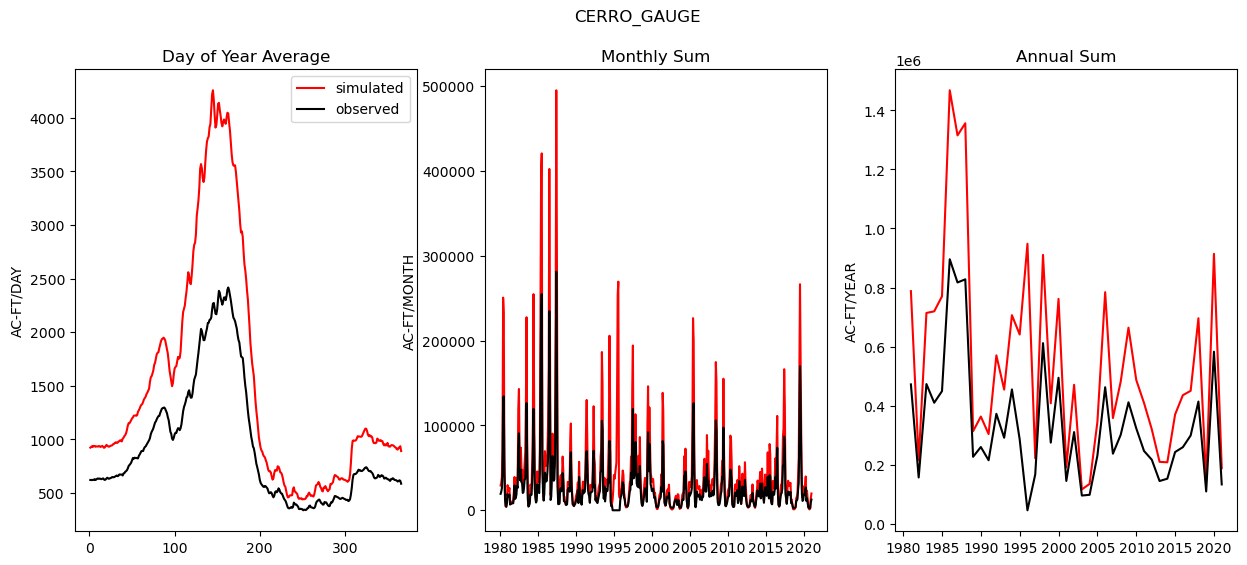

In [7]:
# Check cerro gauge (sum of lobatos & rio pueblo taos inflows) - dropna bc 366 Nan values in the observed timeseries
cerro_data = pd.read_csv("../data/gauge_data/08263500_RIO_GRANDE_NEAR_CERRO.csv", index_col = "date", parse_dates = True)["1980":] * 1.983  #convert from cfsd to ac-ft/day
plot_daily_monthly_annually("CERRO_GAUGE", cerro_data.dropna())

In [8]:
# URG1 and URG2 Irrigation districts are in this file but we have no observations

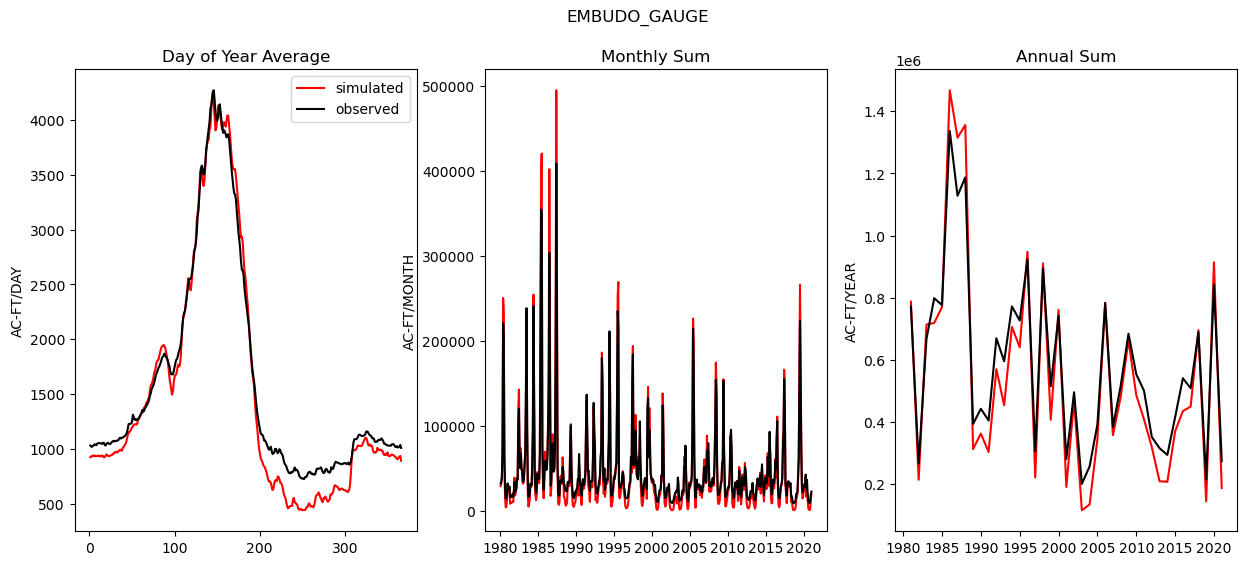

In [9]:
# Check embudo gauge (after cerro gauge, between URG1 & URG2 irrigation districts)
embudo_data = pd.read_csv("../data/gauge_data/08279500_RIO_GRANDE_AT_EMBUDO.csv", index_col = "date", parse_dates = True)["1980":] * 1.983 #convert from cfsd to ac-ft/day
plot_daily_monthly_annually("EMBUDO_GAUGE", embudo_data)

In [10]:
# SAN JUAN CHAMA JSON FILE

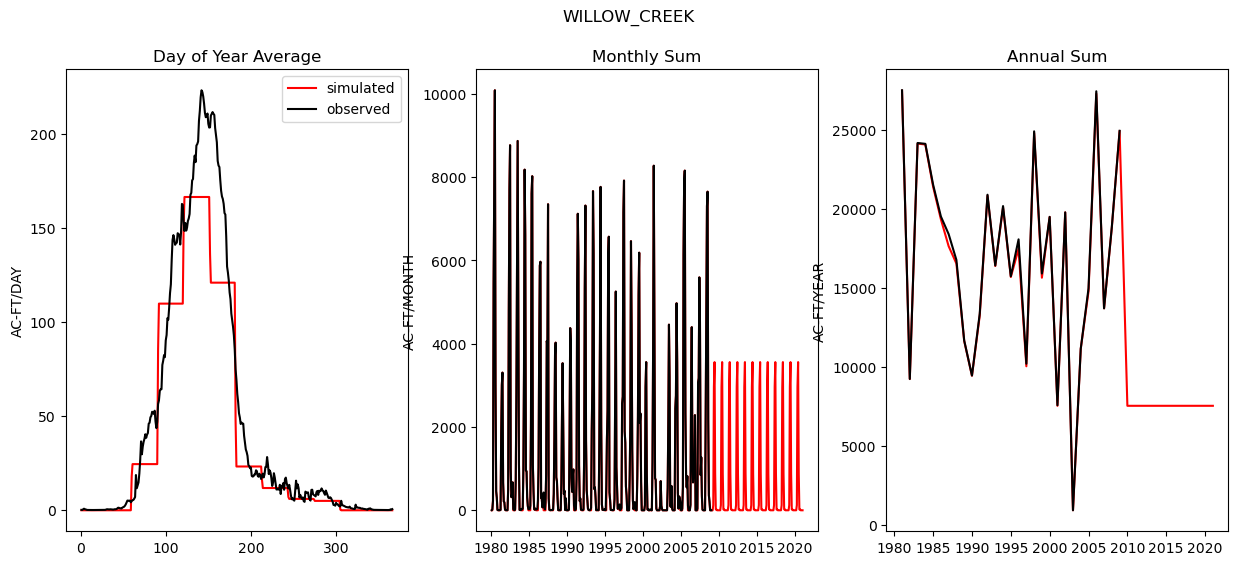

In [11]:
# Check willow creek gauge (beginning of sanjuan_chama json)
willowcreek_data = pd.read_csv("../data/gauge_data/08284200_WILLOW_CREEK_ABOVE_HERON_LOS_OJO.csv", index_col = "date", parse_dates = True)["1980":] * 1.983 * 0.17 #convert from cfsd to ac-ft/day & 17% because not all goes to heron
plot_daily_monthly_annually("WILLOW_CREEK", willowcreek_data)

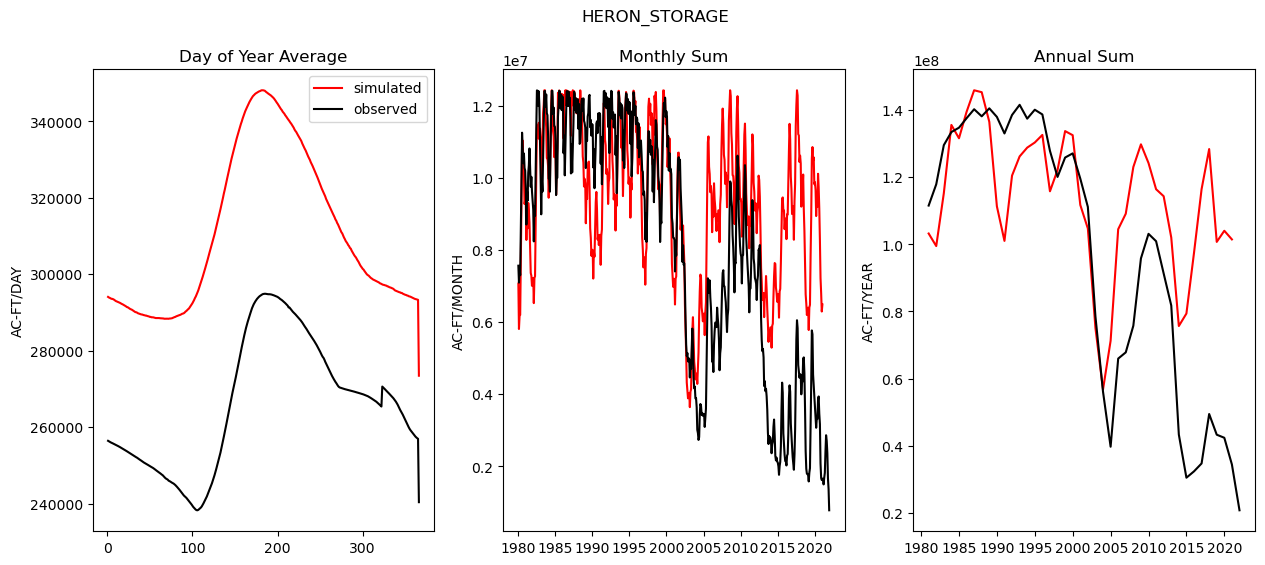

In [12]:
# Check heron reservoir storage
heron_storage = pd.read_csv("../input/reservoirs/heron/obs_storage.csv", index_col = "datetime", parse_dates = True)["1980":]
plot_daily_monthly_annually("HERON_STORAGE", heron_storage)

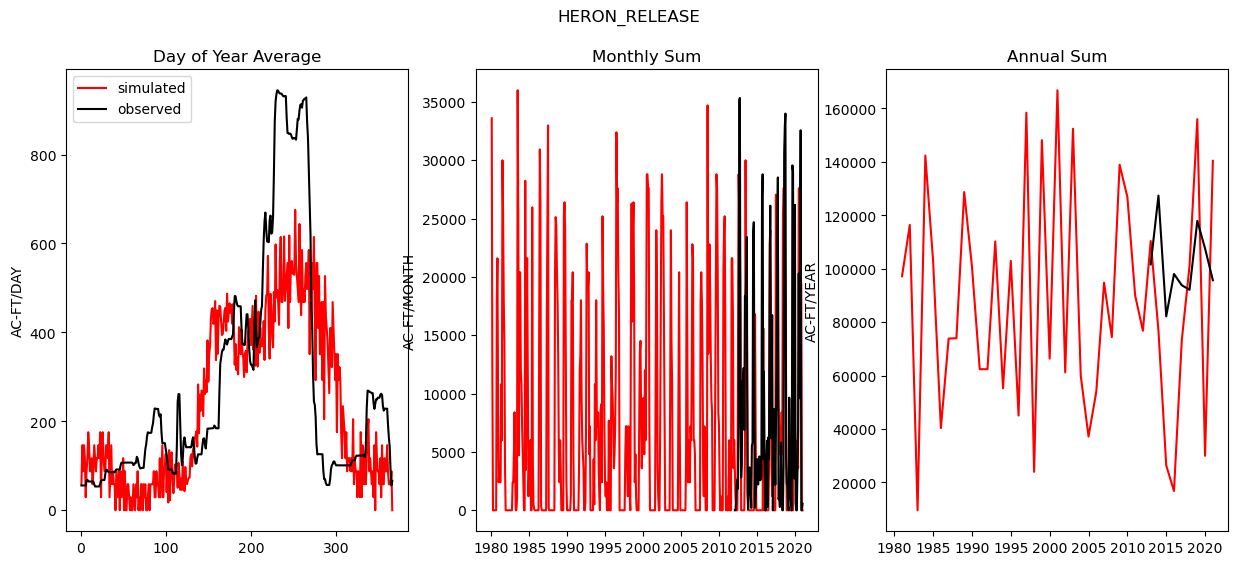

In [13]:
# Check heron reservoir release
heron_release = pd.read_csv("../input/reservoirs/heron/obs_release.csv", index_col = "date", parse_dates = True)["1980":] * 1.983#convert from cfsd to ac-ft/day
plot_daily_monthly_annually("HERON_RELEASE", heron_release)

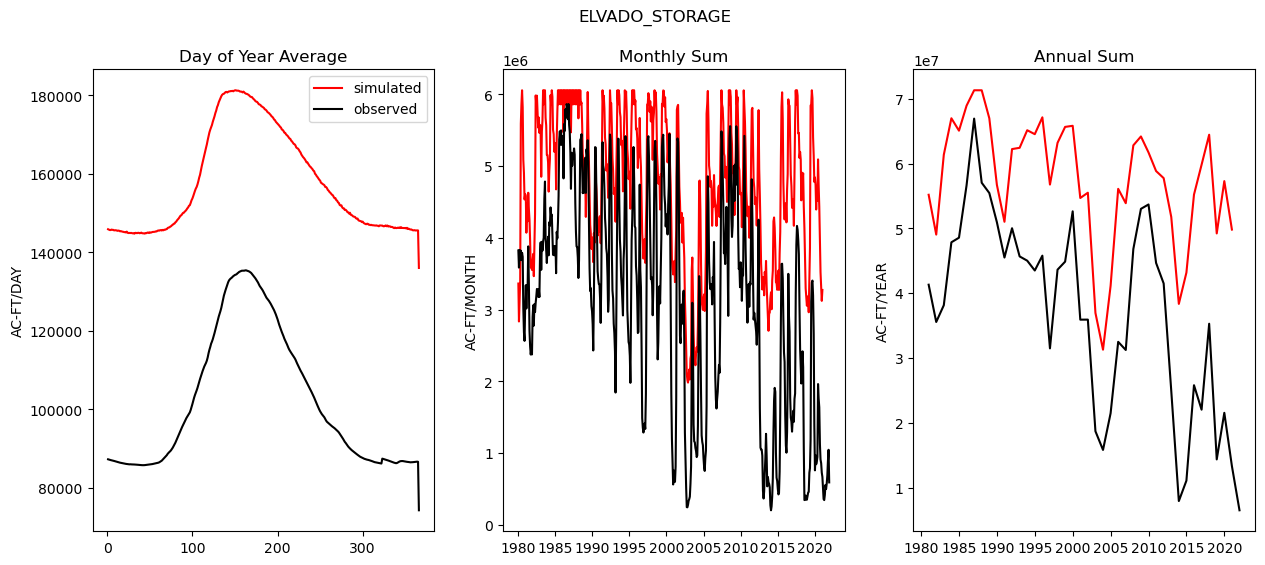

In [14]:
# Check el vado reservoir storage
elvado_storage = pd.read_csv("../input/reservoirs/el_vado/obs_storage.csv", index_col = "datetime", parse_dates = True)["1980":] #convert from cfsd to ac-ft/day
plot_daily_monthly_annually("ELVADO_STORAGE", elvado_storage)

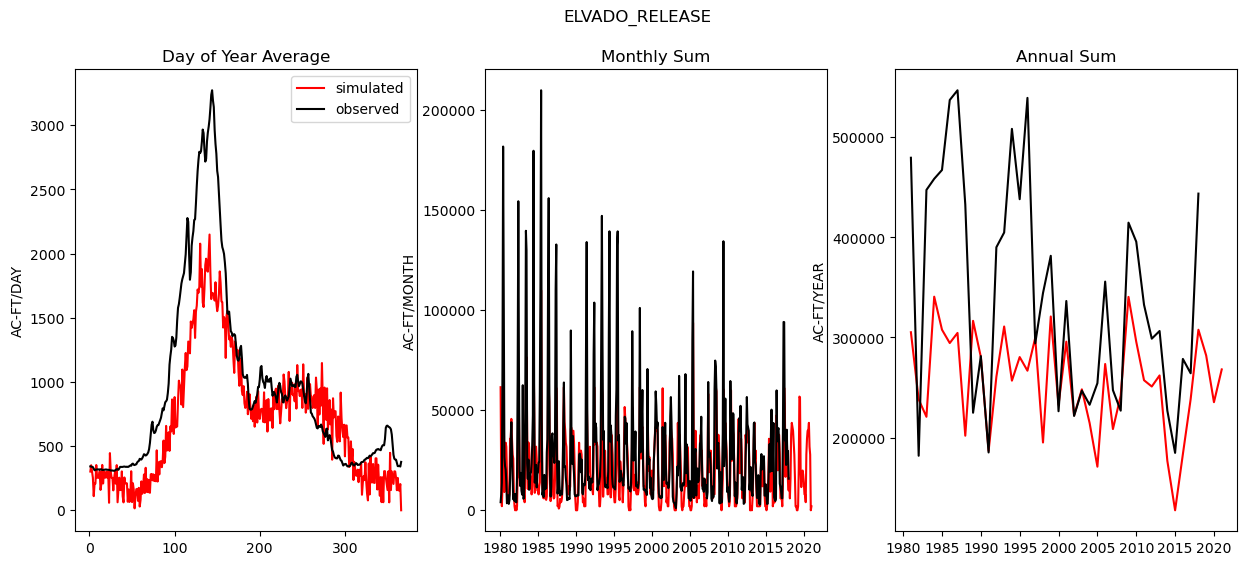

In [15]:
# Check el vado reservoir release
elvado_release = pd.read_csv("../input/reservoirs/el_vado/obs_release.csv", index_col = "date", parse_dates = True)["1980":] * 1.983#convert from cfsd to ac-ft/day
plot_daily_monthly_annually("ELVADO_RELEASE", elvado_release)

In [16]:
# UPPERCHAMMA (between el vado & abiquiu) and LOWERCHAMA (between abiquiu & chochiti) Irrigation districts are in this file but we have no observations

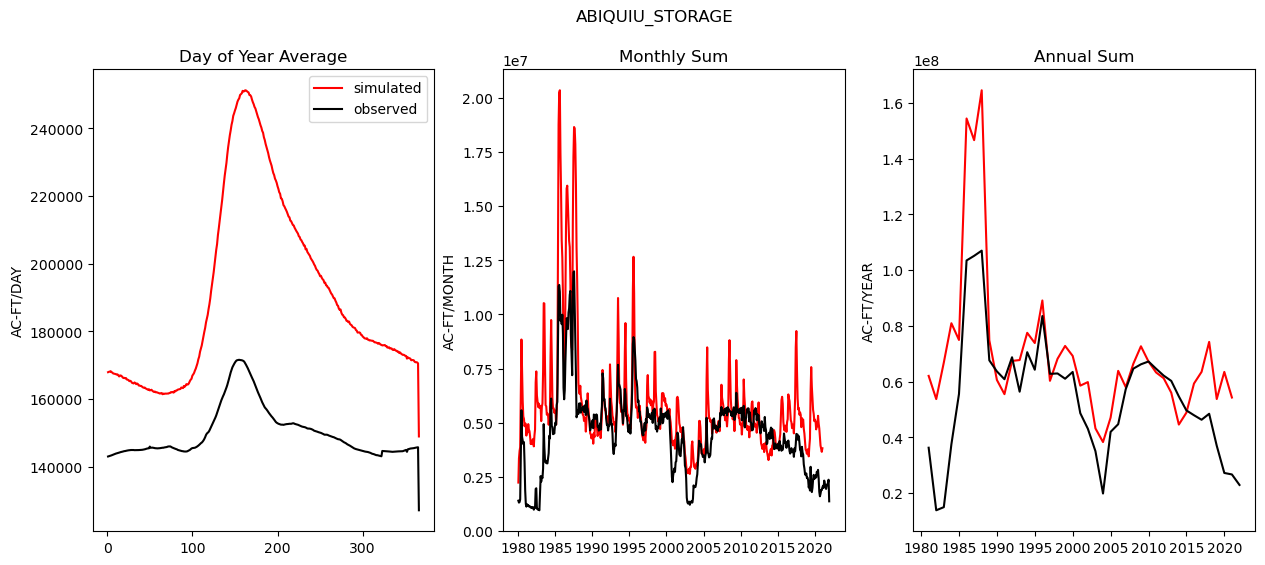

In [17]:
# Check abiquiu reservoir storage
abiquiu_storage = pd.read_csv("../input/reservoirs/abiquiu/obs_storage.csv", index_col = "datetime", parse_dates = True)["1980":] #convert from cfsd to ac-ft/day
plot_daily_monthly_annually("ABIQUIU_STORAGE", abiquiu_storage)

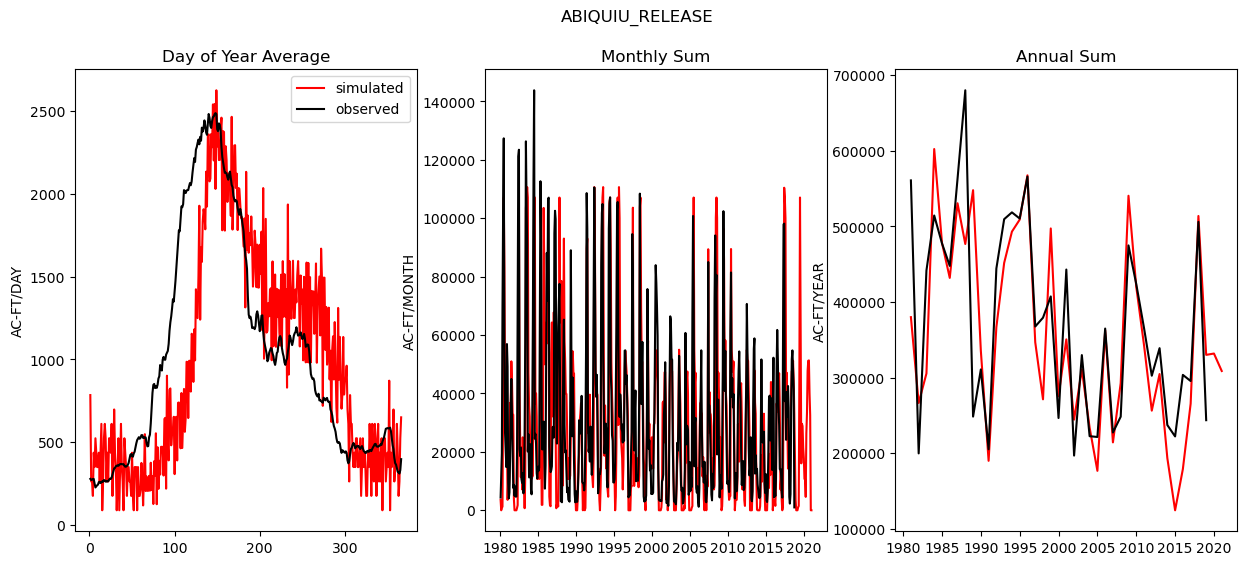

In [18]:
# Check abiquiu reservoir release
abiquiu_release = pd.read_csv("../input/reservoirs/abiquiu/obs_release.csv", index_col = "date", parse_dates = True)["1980":] * 1.983#convert from cfsd to ac-ft/day
plot_daily_monthly_annually("ABIQUIU_RELEASE", abiquiu_release)

In [19]:
# now in the MRGCD json file, beginning at Cochiti and ending just upstream of elephant butte

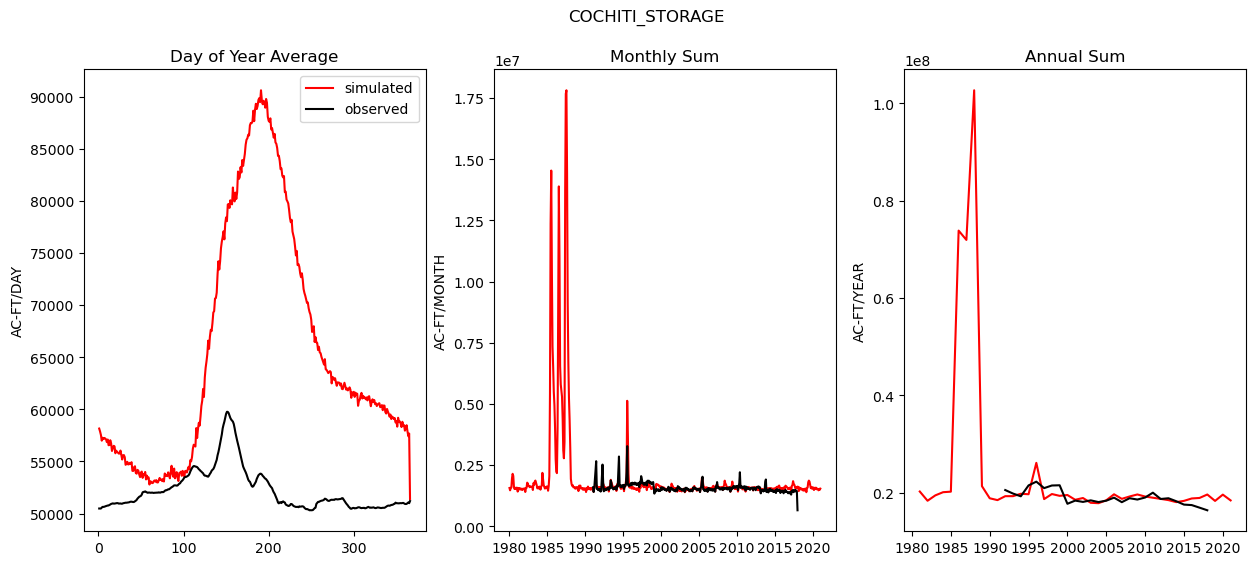

In [20]:
# Check cochiti reservoir storage - .dropna() on dataset b/c only data between 1991 and 2017
cochiti_storage = pd.read_csv("../input/reservoirs/cochiti/obs_storage.csv", index_col = "date", parse_dates = True)["1980":] #convert from cfsd to ac-ft/day
plot_daily_monthly_annually("COCHITI_STORAGE", cochiti_storage.dropna())

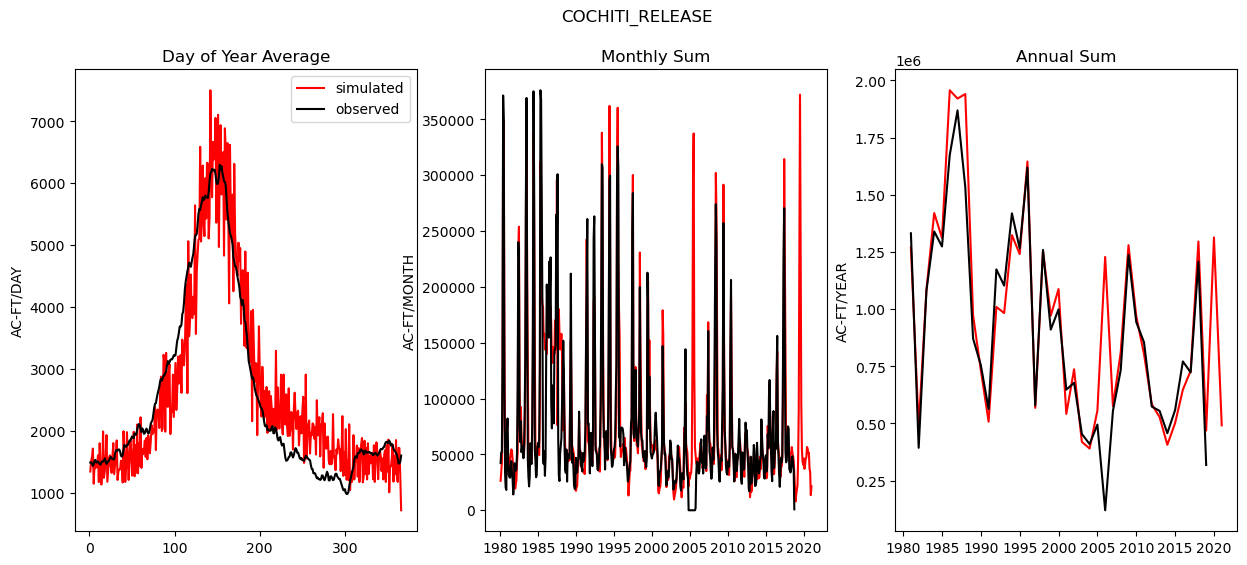

In [21]:
# Check cochiti reservoir release, dropna bc 365 NaN values
cochiti_release = pd.read_csv("../input/reservoirs/cochiti/obs_release.csv", index_col = "date", parse_dates = True)["1980":] * 1.983#convert from cfsd to ac-ft/day
plot_daily_monthly_annually("COCHITI_RELEASE", cochiti_release.dropna())

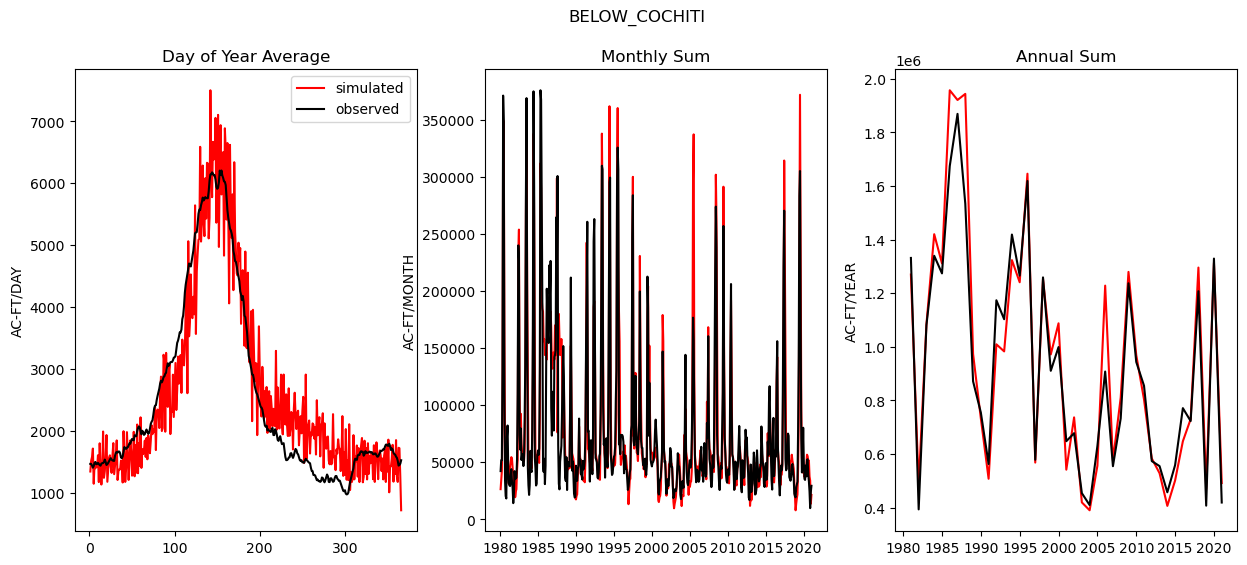

In [22]:
# Check below cochiti gauge 
belowcochiti_data = pd.read_csv("../data/gauge_data/08317400_RIO_GRANDE_BELOW_COCHITI_DAM_fill.csv", index_col = "date", parse_dates = True)["1980":] * 1.983 #convert from cfsd to ac-ft/day 
plot_daily_monthly_annually("BELOW_COCHITI", belowcochiti_data)

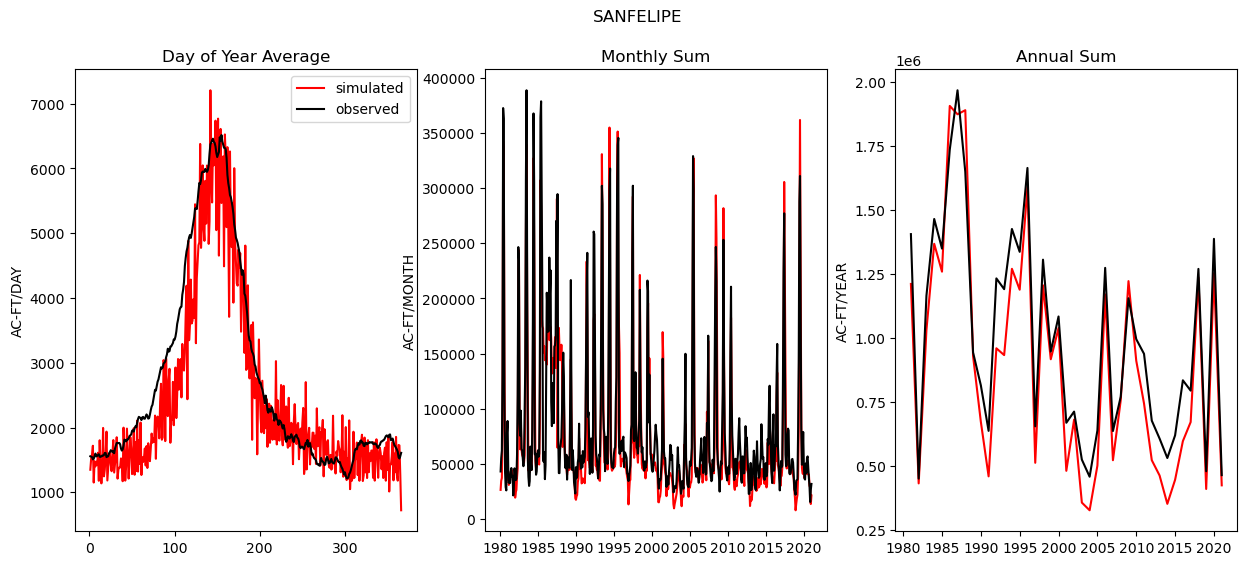

In [23]:
# Check san felipe gauge 
sanfelipe_data = pd.read_csv("../data/gauge_data/08319000_RIO_GRANDE_AT_SAN_FELIPE_fill.csv", index_col = "date", parse_dates = True)["1980":] * 1.983  #convert from cfsd to ac-ft/day 
plot_daily_monthly_annually("SANFELIPE", sanfelipe_data)

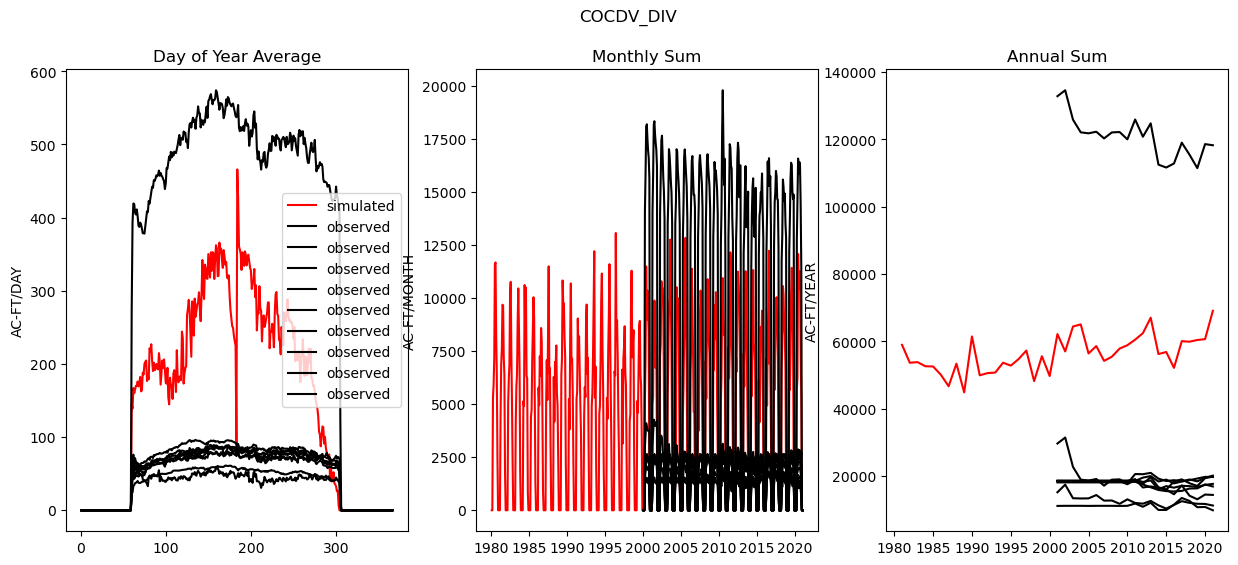

In [24]:
# Check COCDV Irrigation district diversions
COCDCdiv_data = pd.read_csv("../data/irr_data/cocdv/COCHITI_DIV_filled_.csv", index_col = "date", parse_dates = True)["1980":] #convert from cfsd to ac-ft/day
plot_daily_monthly_annually("COCDV_DIV", COCDCdiv_data)

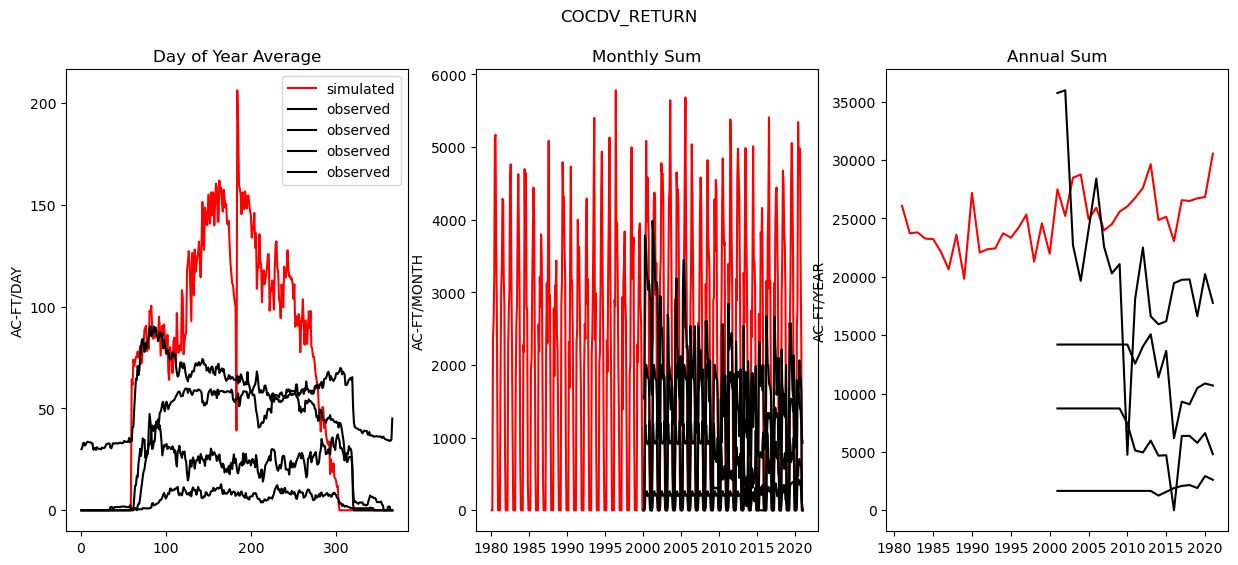

In [25]:
# Check COCDV Irrigation district diversions
COCDCret_data = pd.read_csv("../data/irr_data/cocdv/COCHITI_RET_filled_.csv", index_col = "date", parse_dates = True)["1980":] * 1.983  #convert from cfsd to ac-ft/day
plot_daily_monthly_annually("COCDV_RETURN", COCDCret_data)

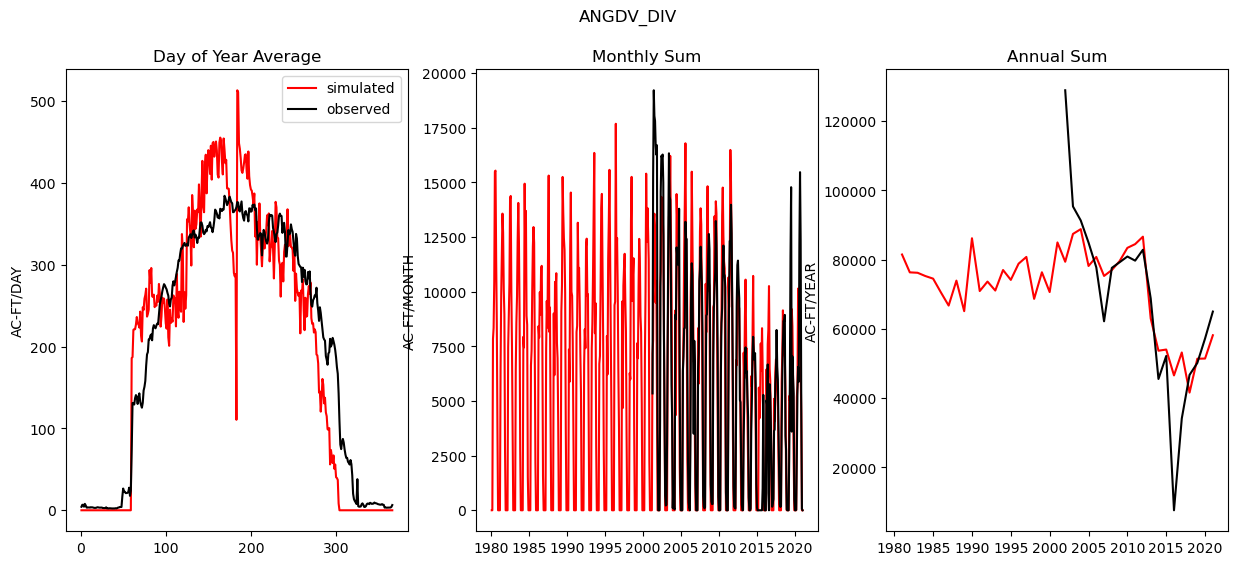

In [26]:
# Check ANGDV Irrigation district withdrals
ANGDVw_data = pd.read_csv("../data/irr_data/angdv/ANGDV_withdrawls.csv", index_col = "date", parse_dates = True, usecols = ['date', 'Discharge'])["1980":] * 1.983  #convert from cfsd to ac-ft/day
# drop Nan from the dataset
ANGDVw_data = ANGDVw_data.dropna()
# drop negative flows from the dataset
ANGDVw_data["Discharge"] = ANGDVw_data["Discharge"].clip(lower=0)
# there are hourly values in this dataset, so group by day and take the mean so we have 1 value per day
ANGDVw_date = ANGDVw_data.groupby(ANGDVw_data.index.date).mean()
ANGDVw_date.index = pd.to_datetime(ANGDVw_date.index)
plot_daily_monthly_annually("ANGDV_DIV", ANGDVw_date)

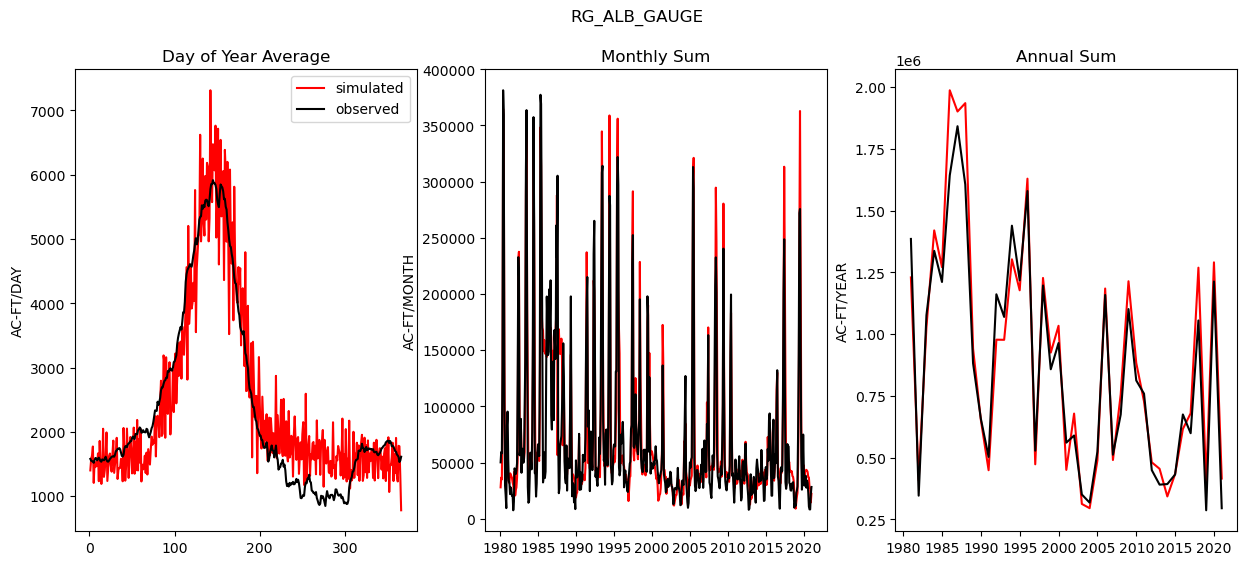

In [27]:
# Check rio grande at albuqueque gauge 
alb_gauge = pd.read_csv("../data/gauge_data/08330000_RIO_GRANDE_AT_ALBUQUERQUE.csv", index_col = "date", parse_dates = True)["1980":] * 1.983 #convert from cfsd to ac-ft/day 
plot_daily_monthly_annually("RG_ALB_GAUGE", alb_gauge)

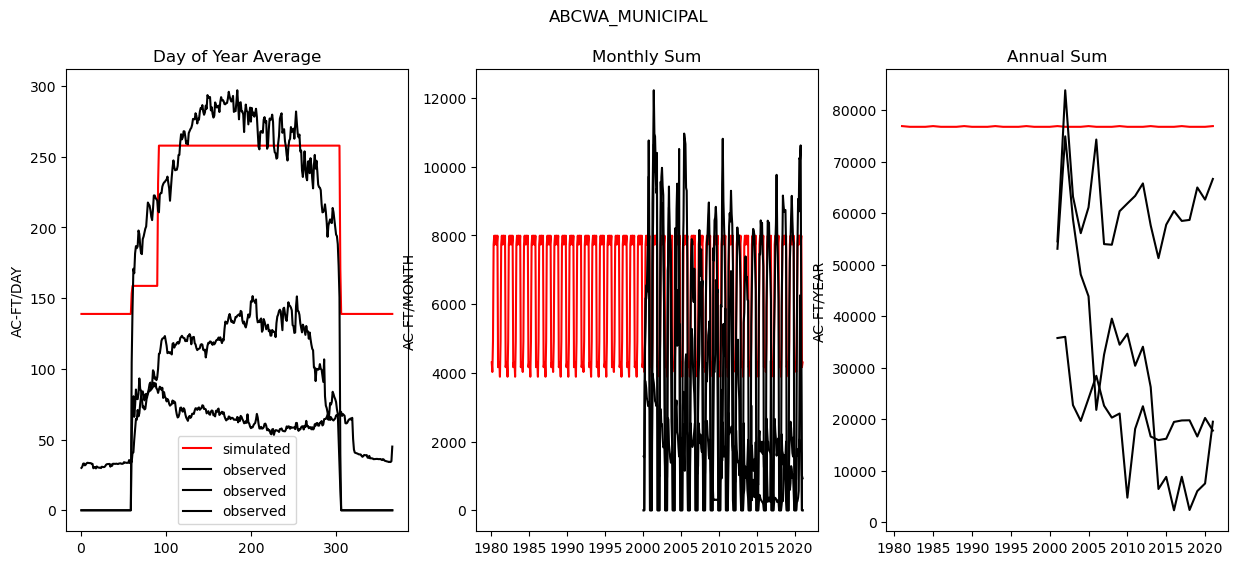

In [28]:
# Check albuquerque municipal demands/outlet
alb_div = pd.read_csv("../data/municipal_data/abcwa/ALB_DIV_filled.csv", index_col = "date", parse_dates = True)["1980":] * 1.983 #convert from cfsd to ac-ft/day 
plot_daily_monthly_annually("ABCWA_MUNICIPAL", alb_div)

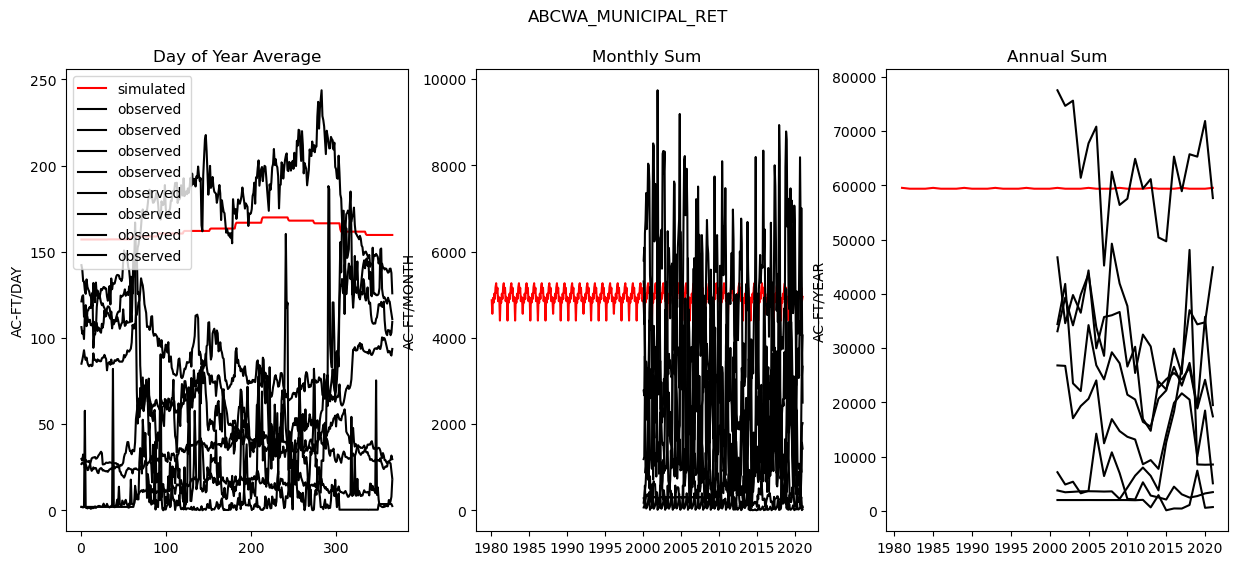

In [29]:
# Check albuquerque municipal return flows
alb_ret = pd.read_csv("../data/municipal_data/abcwa/ALB_RET_filled.csv", index_col = "date", parse_dates = True)["1980":] * 1.983 #convert from cfsd to ac-ft/day 
plot_daily_monthly_annually("ABCWA_MUNICIPAL_RET", alb_ret)

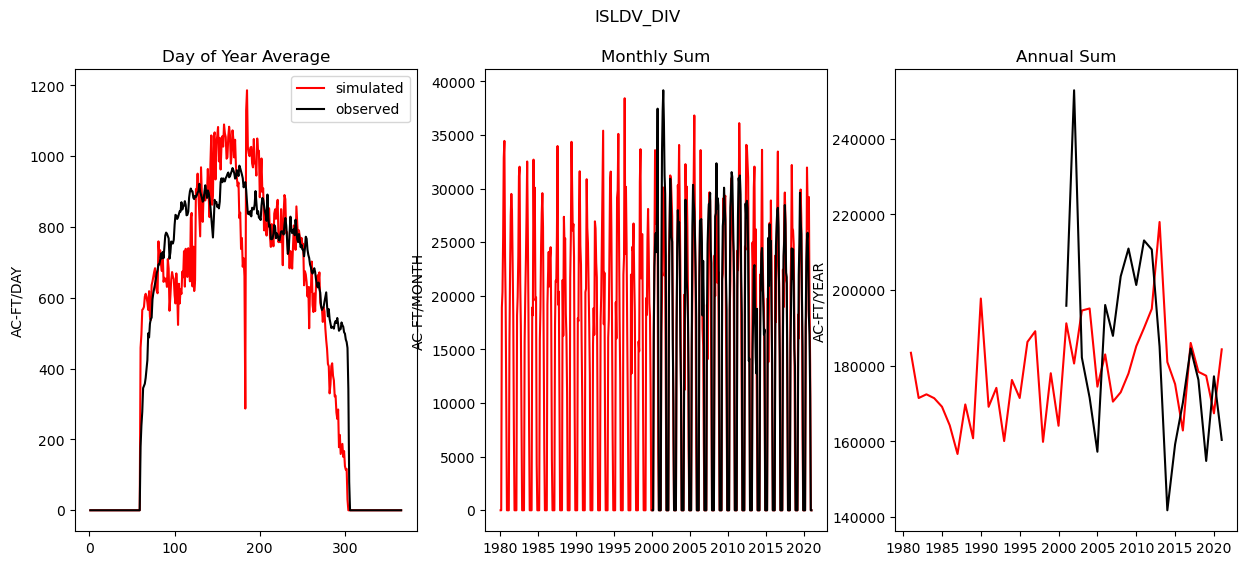

In [30]:
# Check  ISLDV Irrigation district withdrals
ISLDVw_data = pd.read_csv("../data/irr_data/isldv/BELEN_DIV_filled.csv", index_col = "date", parse_dates = True)["1980":] * 1.983  #convert from cfsd to ac-ft/day
# sum the columns? this is an (unchecked) assumption that the columns in here equal the total divserions
ISLDVw_data['total'] = ISLDVw_data.sum(axis = 1)
plot_daily_monthly_annually("ISLDV_DIV", ISLDVw_data['total'])

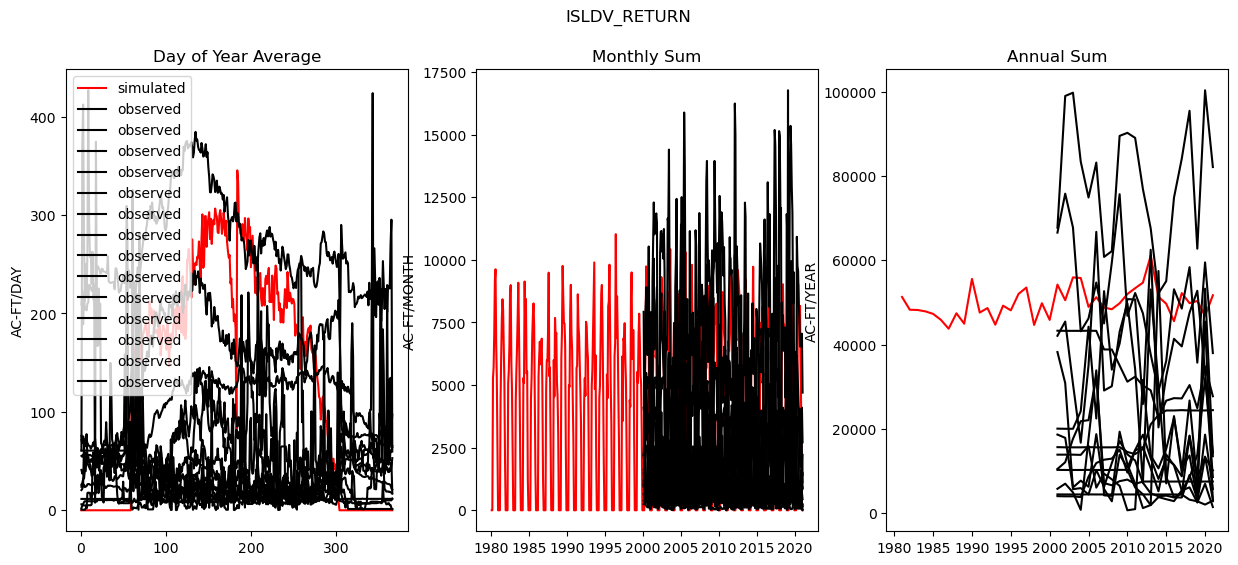

In [31]:
# Check  ISLDV Irrigation district returns - figure out if belen div/flows  - isleta 
ISLDVr_data = pd.read_csv("../data/irr_data/isldv/BELEN_RET_filled.csv", index_col = "date", parse_dates = True)["1980":] * 1.983  #convert from cfsd to ac-ft/day
# the assumption made for ISLDV returns does not hold for ISLDV returns, but there are more & different columns here than above
plot_daily_monthly_annually("ISLDV_RETURN", ISLDVr_data)

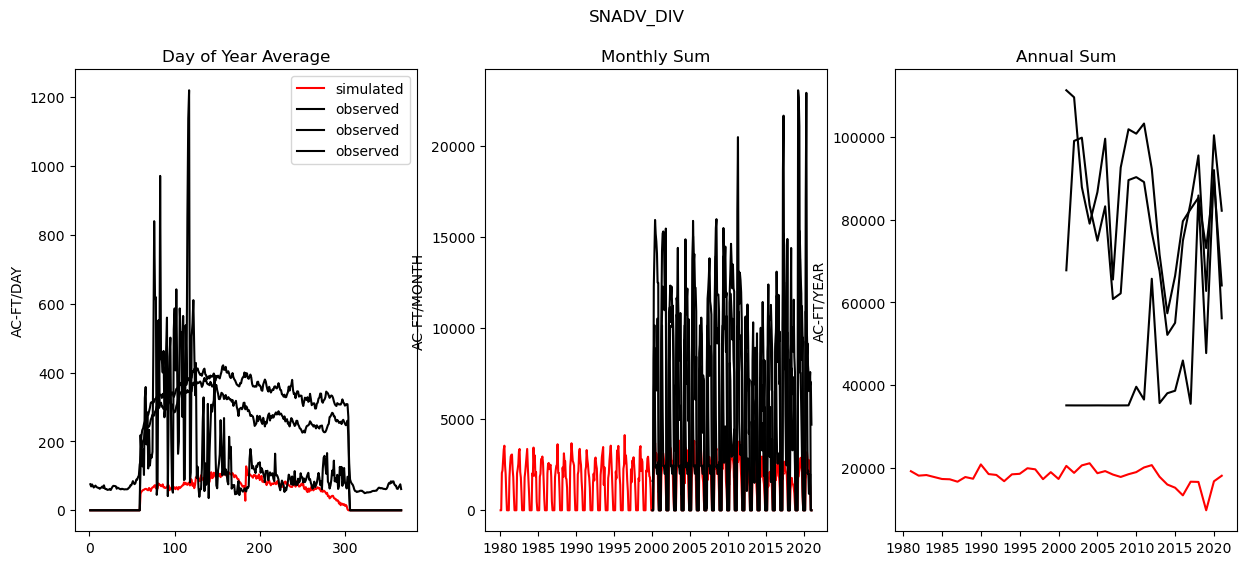

In [32]:
# Check SNADC Irrigation district withdrals -
SNADVw_data = pd.read_csv("../data/irr_data/snadv/SOCORRO_DIV_filled.csv", index_col = "date", parse_dates = True)["1980":] * 1.983  #convert from cfsd to ac-ft/day
plot_daily_monthly_annually("SNADV_DIV", SNADVw_data)

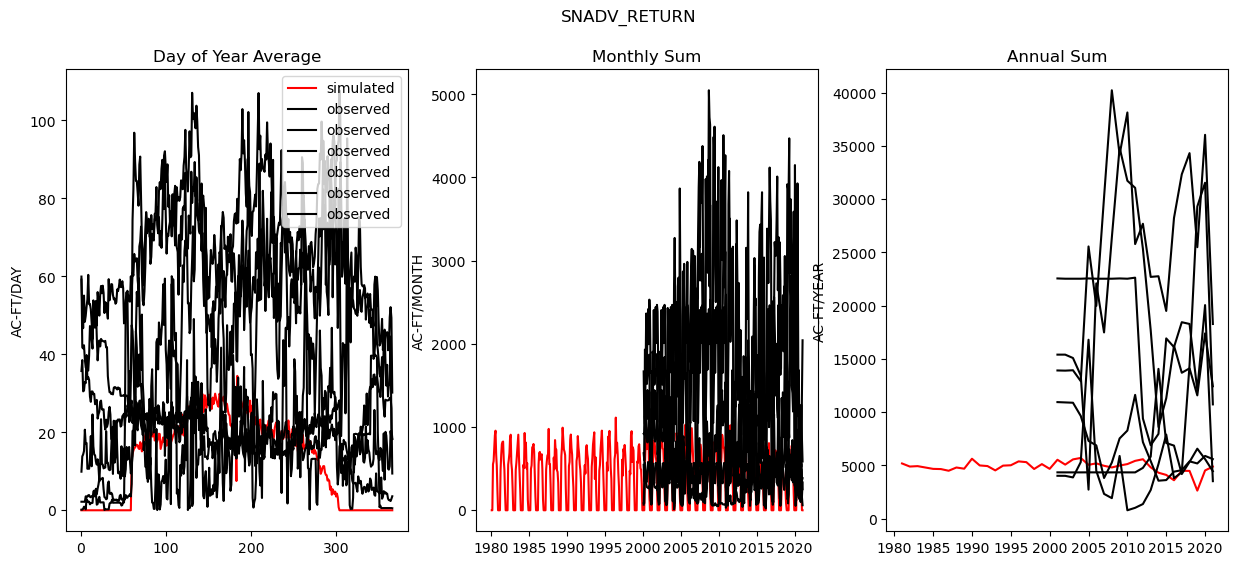

In [33]:
# Check  SNADV Irrigation district returns - figure out if belen div/flows  - isleta 
SNADVr_data = pd.read_csv("../data/irr_data/snadv/SOCORRO_RET_filled.csv", index_col = "date", parse_dates = True)["1980":] * 1.983  #convert from cfsd to ac-ft/day
plot_daily_monthly_annually("SNADV_RETURN", SNADVr_data)

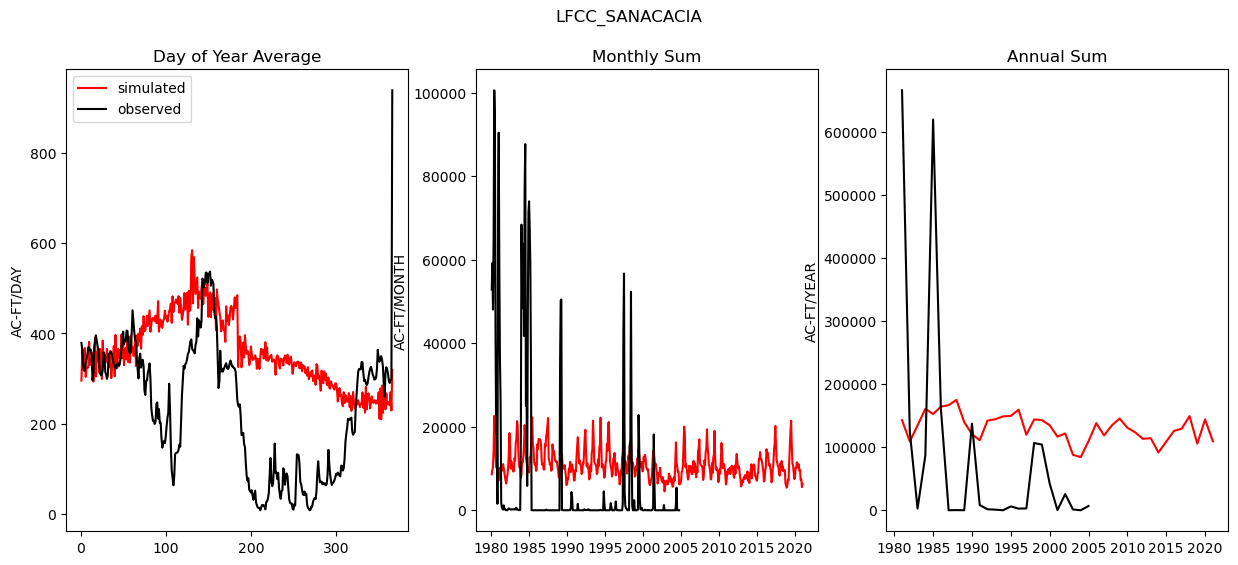

In [34]:
# Check rio grande at lfcc san acacia
lfcc_gauge = pd.read_csv("../data/gauge_data/08354800_RIO_GRANDE_CONVEYANCE_CHANNEL_AT_SAN_ACACIA.csv", index_col = "date", parse_dates = True)["1980":] * 1.983 #convert from cfsd to ac-ft/day 
plot_daily_monthly_annually("LFCC_SANACACIA", lfcc_gauge)

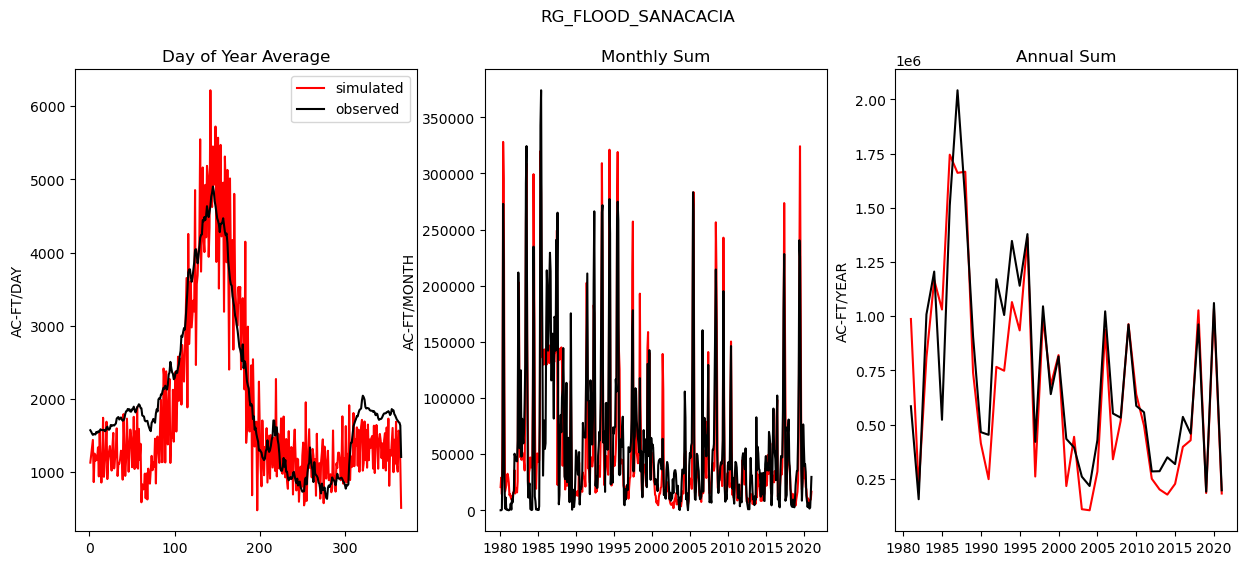

In [35]:
# Check rio grande at san acacia floodway
sanacacia_gauge = pd.read_csv("../data/gauge_data/08354900_RIO_GRANDE_FLOODWAY_AT SAN_ACACIA.csv", index_col = "date", parse_dates = True)["1980":] * 1.983 #convert from cfsd to ac-ft/day 
plot_daily_monthly_annually("RG_FLOOD_SANACACIA", sanacacia_gauge.dropna())

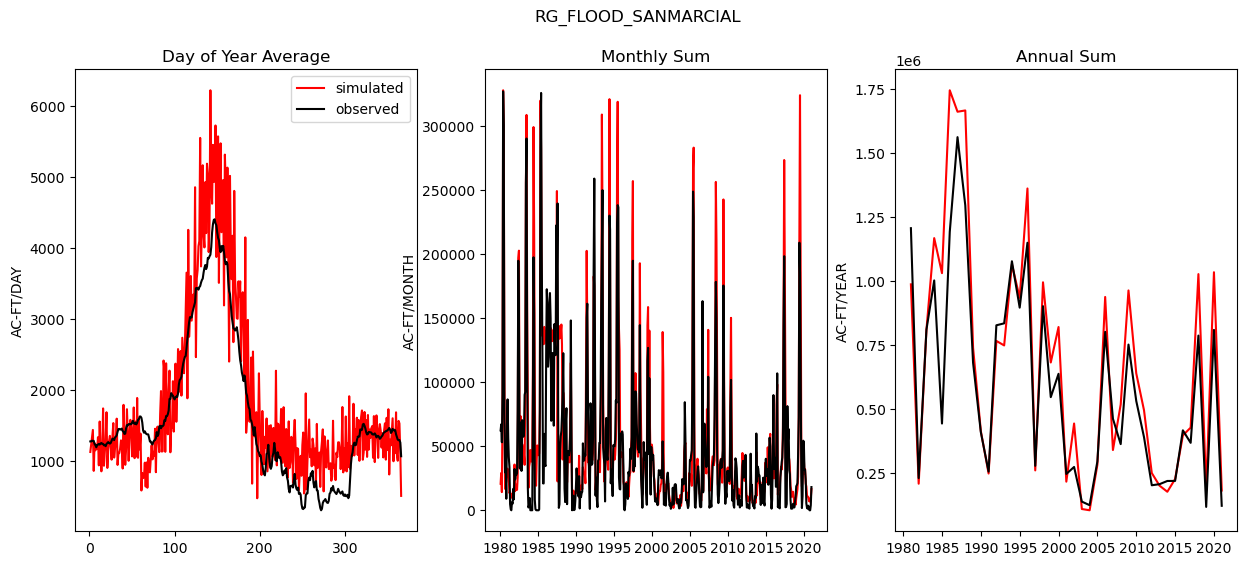

In [36]:
# Check rio grande at san acacia floodway
sanmarcial_gauge = pd.read_csv("../data/gauge_data/08358400_RIO_GRANDE_FLOODWAY_AT_SAN_MARCIAL_fill.csv", index_col = "date", parse_dates = True)["1980":] * 1.983 #convert from cfsd to ac-ft/day 
plot_daily_monthly_annually("RG_FLOOD_SANMARCIAL", sanmarcial_gauge)

In [37]:
# now in the final, most downstream json file "texas.json"

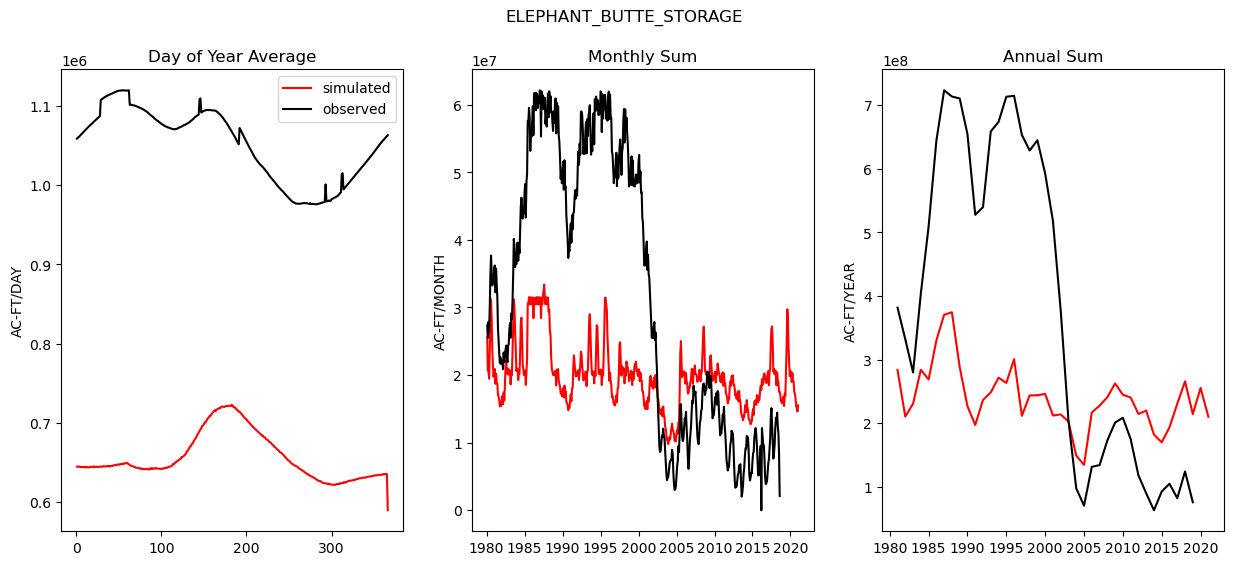

In [38]:
# Check elephant butte reservoir storage
eb_storage = pd.read_csv("../input/reservoirs/elephant_butte/obs_storage.csv", index_col = "date", parse_dates = True)["1980":] #convert from cfsd to ac-ft/day
plot_daily_monthly_annually("ELEPHANT_BUTTE_STORAGE", eb_storage.dropna())

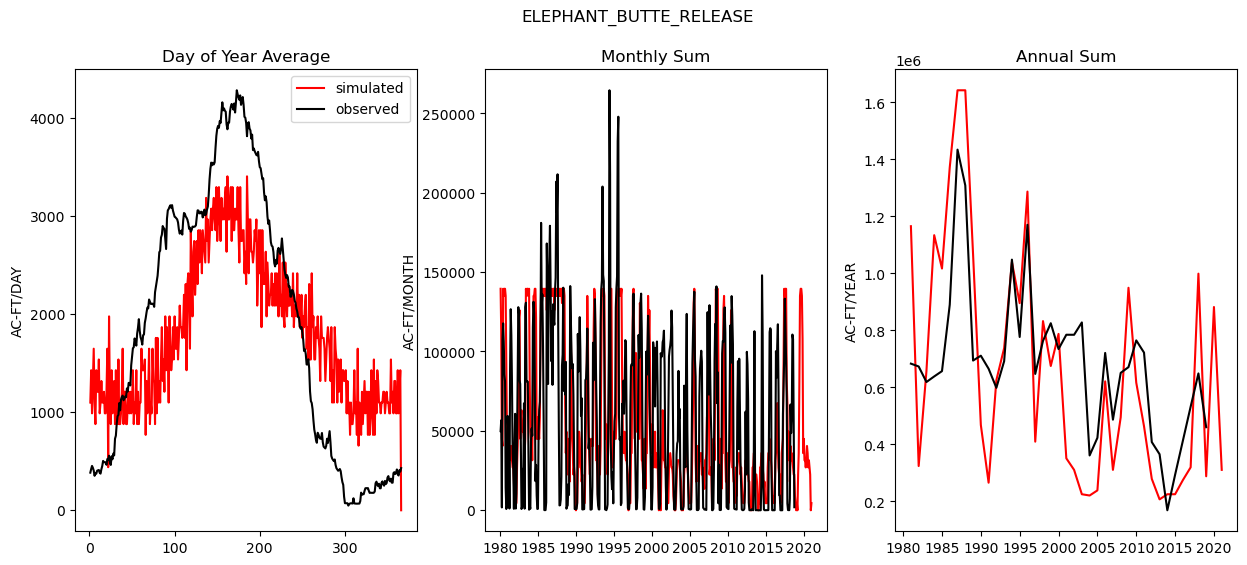

In [39]:
# Check elephant buttee reservoir release
eb_release = pd.read_csv("../input/reservoirs/elephant_butte/obs_release.csv", index_col = "date", parse_dates = True)["1980":] * 1.983#convert from cfsd to ac-ft/day
plot_daily_monthly_annually("ELEPHANT_BUTTE_RELEASE", eb_release)

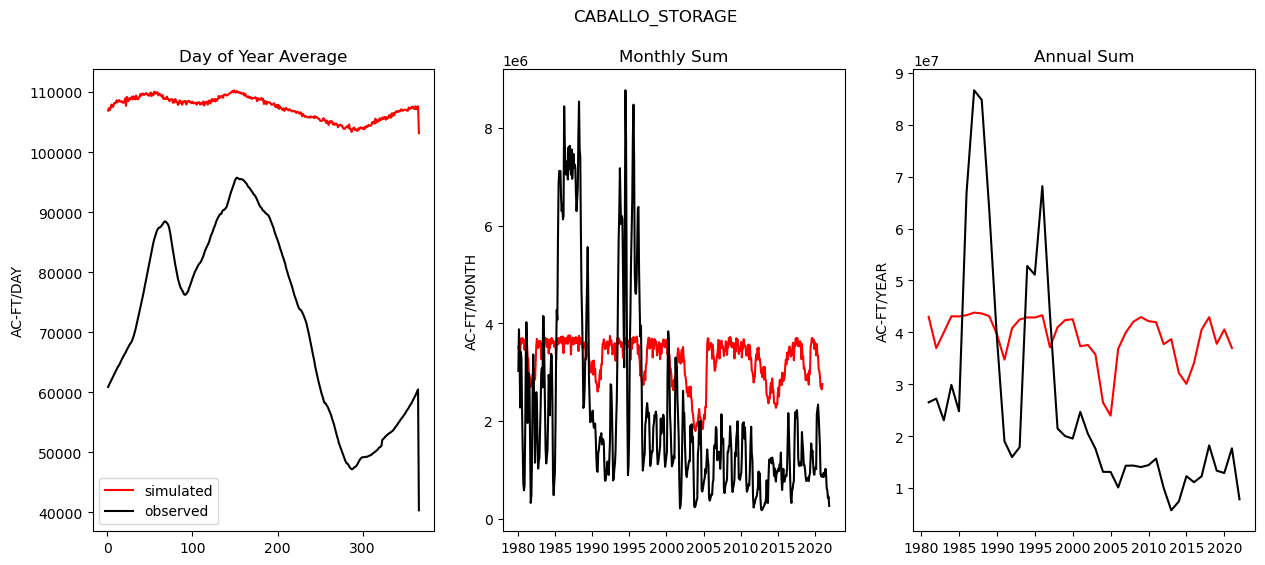

In [40]:
# Check CABALLO reservoir storage
caballo_storage = pd.read_csv("../input/reservoirs/caballo/obs_storage.csv", index_col = "datetime", parse_dates = True)["1980":] #convert from cfsd to ac-ft/day
plot_daily_monthly_annually("CABALLO_STORAGE", caballo_storage)

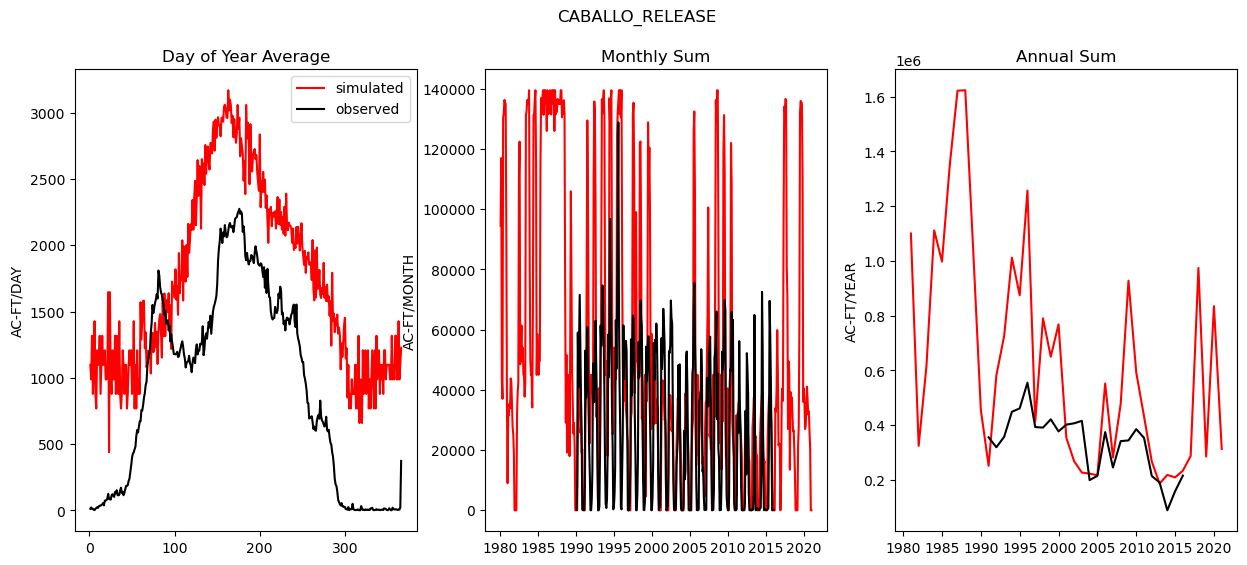

In [41]:
# Check CABALLO reservoir release
caballo_release = pd.read_csv("../input/reservoirs/caballo/obs_release.csv", index_col = "datetime", parse_dates = True)["1980":] #convert from cfsd to ac-ft/day
plot_daily_monthly_annually("CABALLO_RELEASE", caballo_release.dropna())

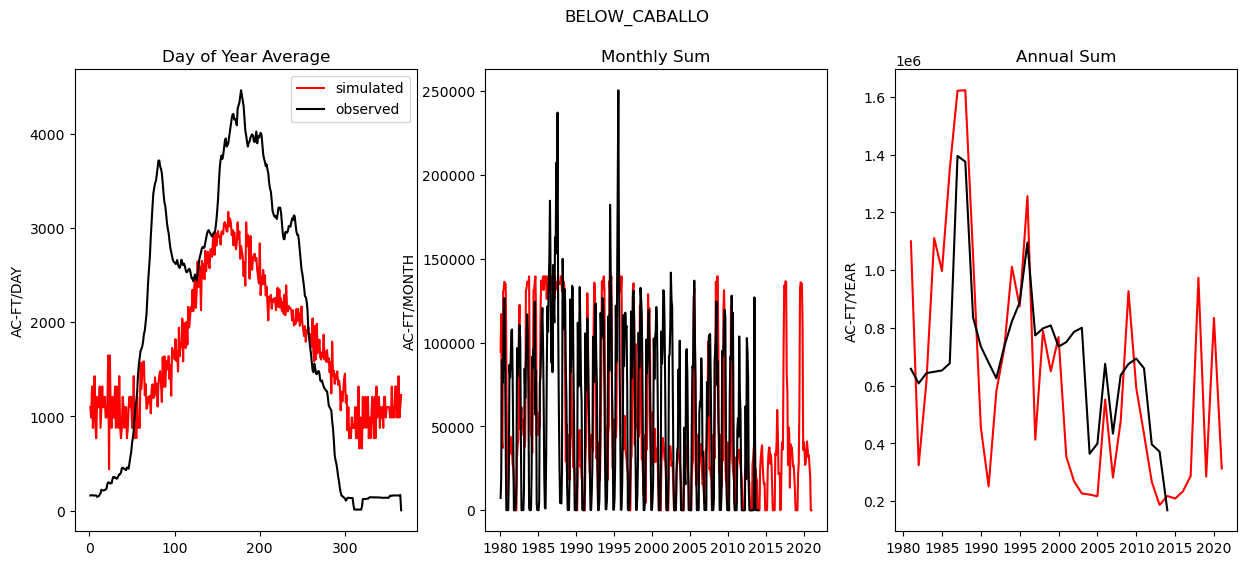

In [42]:
# Check rio grande gauge below caballo dam
below_caballo = pd.read_csv("../data/gauge_data/08362500_RIO_GRANDE_BLW_CABALLO_DAM.csv", index_col = "date", parse_dates = True)["1980":] * 1.983 #convert from cfsd to ac-ft/day 
plot_daily_monthly_annually("BELOW_CABALLO", below_caballo)

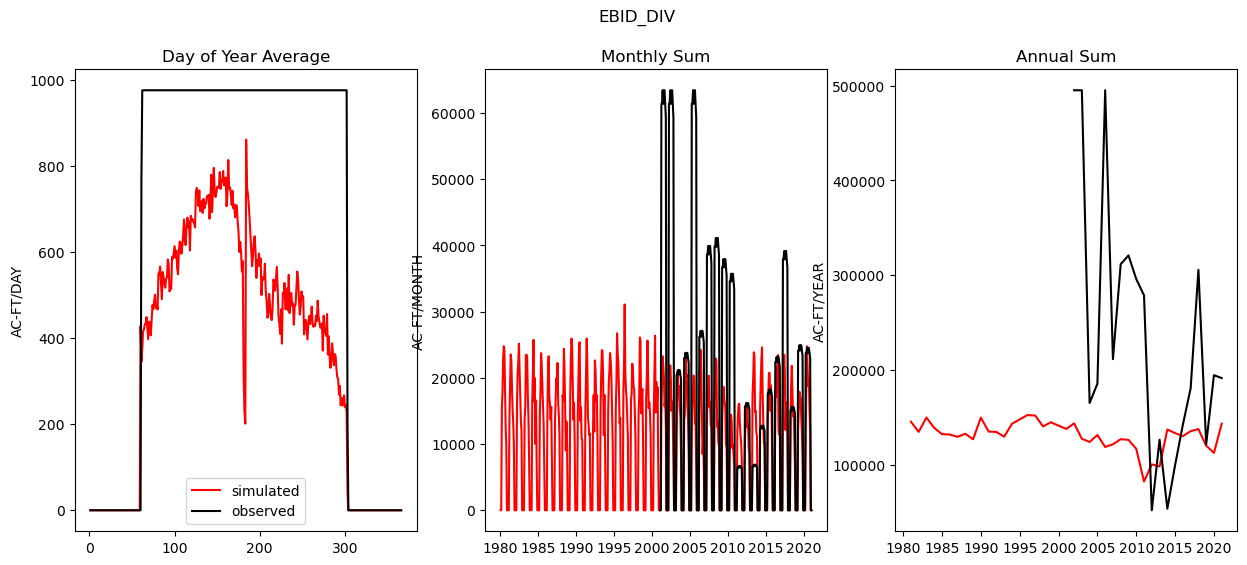

In [43]:
# Check EBID withdrals
EBID_data = pd.read_csv("../data/irr_data/ebid/EBID_DIV_filled.csv", index_col = "date", parse_dates = True)["1980":] * 1.983  #convert from cfsd to ac-ft/day
plot_daily_monthly_annually("EBID_DIV", EBID_data)

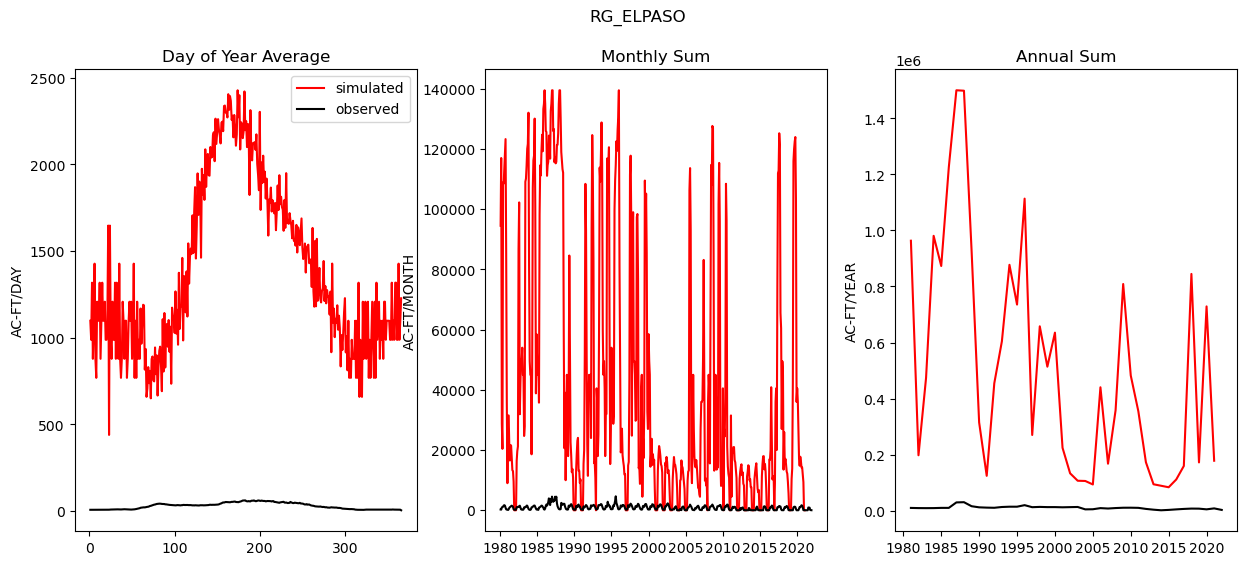

In [44]:
# Check rio grande gauge at el paso
el_paso = pd.read_csv("../data/gauge_data/08364000_RIO_GRANDE_AT_EL_PASO.csv", index_col = "date", parse_dates = True)["1980":] * 1.983 #convert from cfsd to ac-ft/day 
plot_daily_monthly_annually("RG_ELPASO", el_paso)

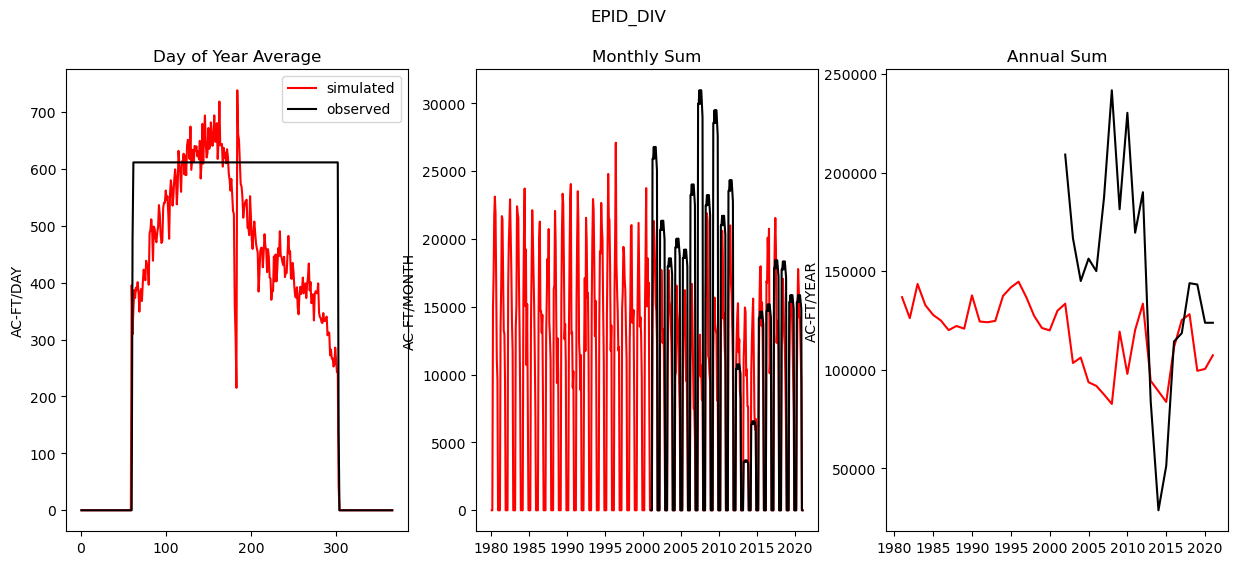

In [45]:
# Check EPID withdrals
EPID_data = pd.read_csv("../data/irr_data/epid/EPID_DIV_filled.csv", index_col = "date", parse_dates = True)["1980":] * 1.983  #convert from cfsd to ac-ft/day
plot_daily_monthly_annually("EPID_DIV", EPID_data)

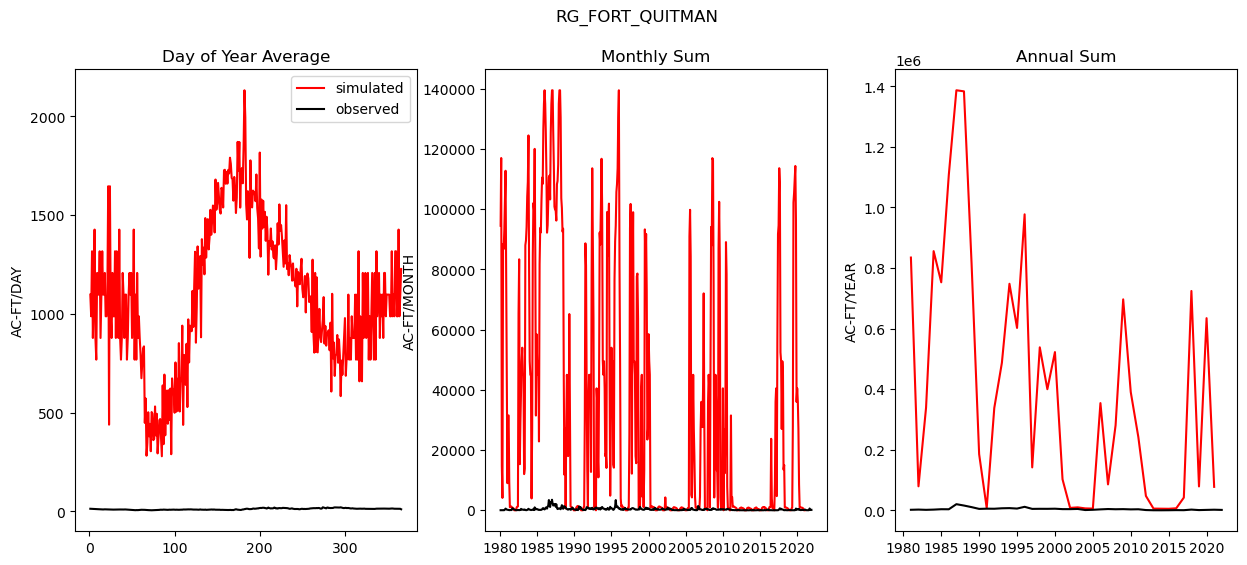

In [46]:
# Check rio grande gauge at fort quitman
fort_quitman = pd.read_csv("../data/gauge_data/08370500_RIO_GRANDE_AT_FORT_QUITMAN.csv", index_col = "date", parse_dates = True)["1980":] * 1.983 #convert from cfsd to ac-ft/day 
plot_daily_monthly_annually("RG_FORT_QUITMAN", fort_quitman)

In [47]:
# RECREATE CHINEDUMS VALIDATION PLOTS FOR RESERVOIR STORAGES & IRRIGATION DISTRICTS 

0 heron HERON
1 el_vado ELVADO
2 abiquiu ABIQUIU
3 cochiti COCHITI
4 elephant_butte ELEPHANT_BUTTE
5 caballo CABALLO


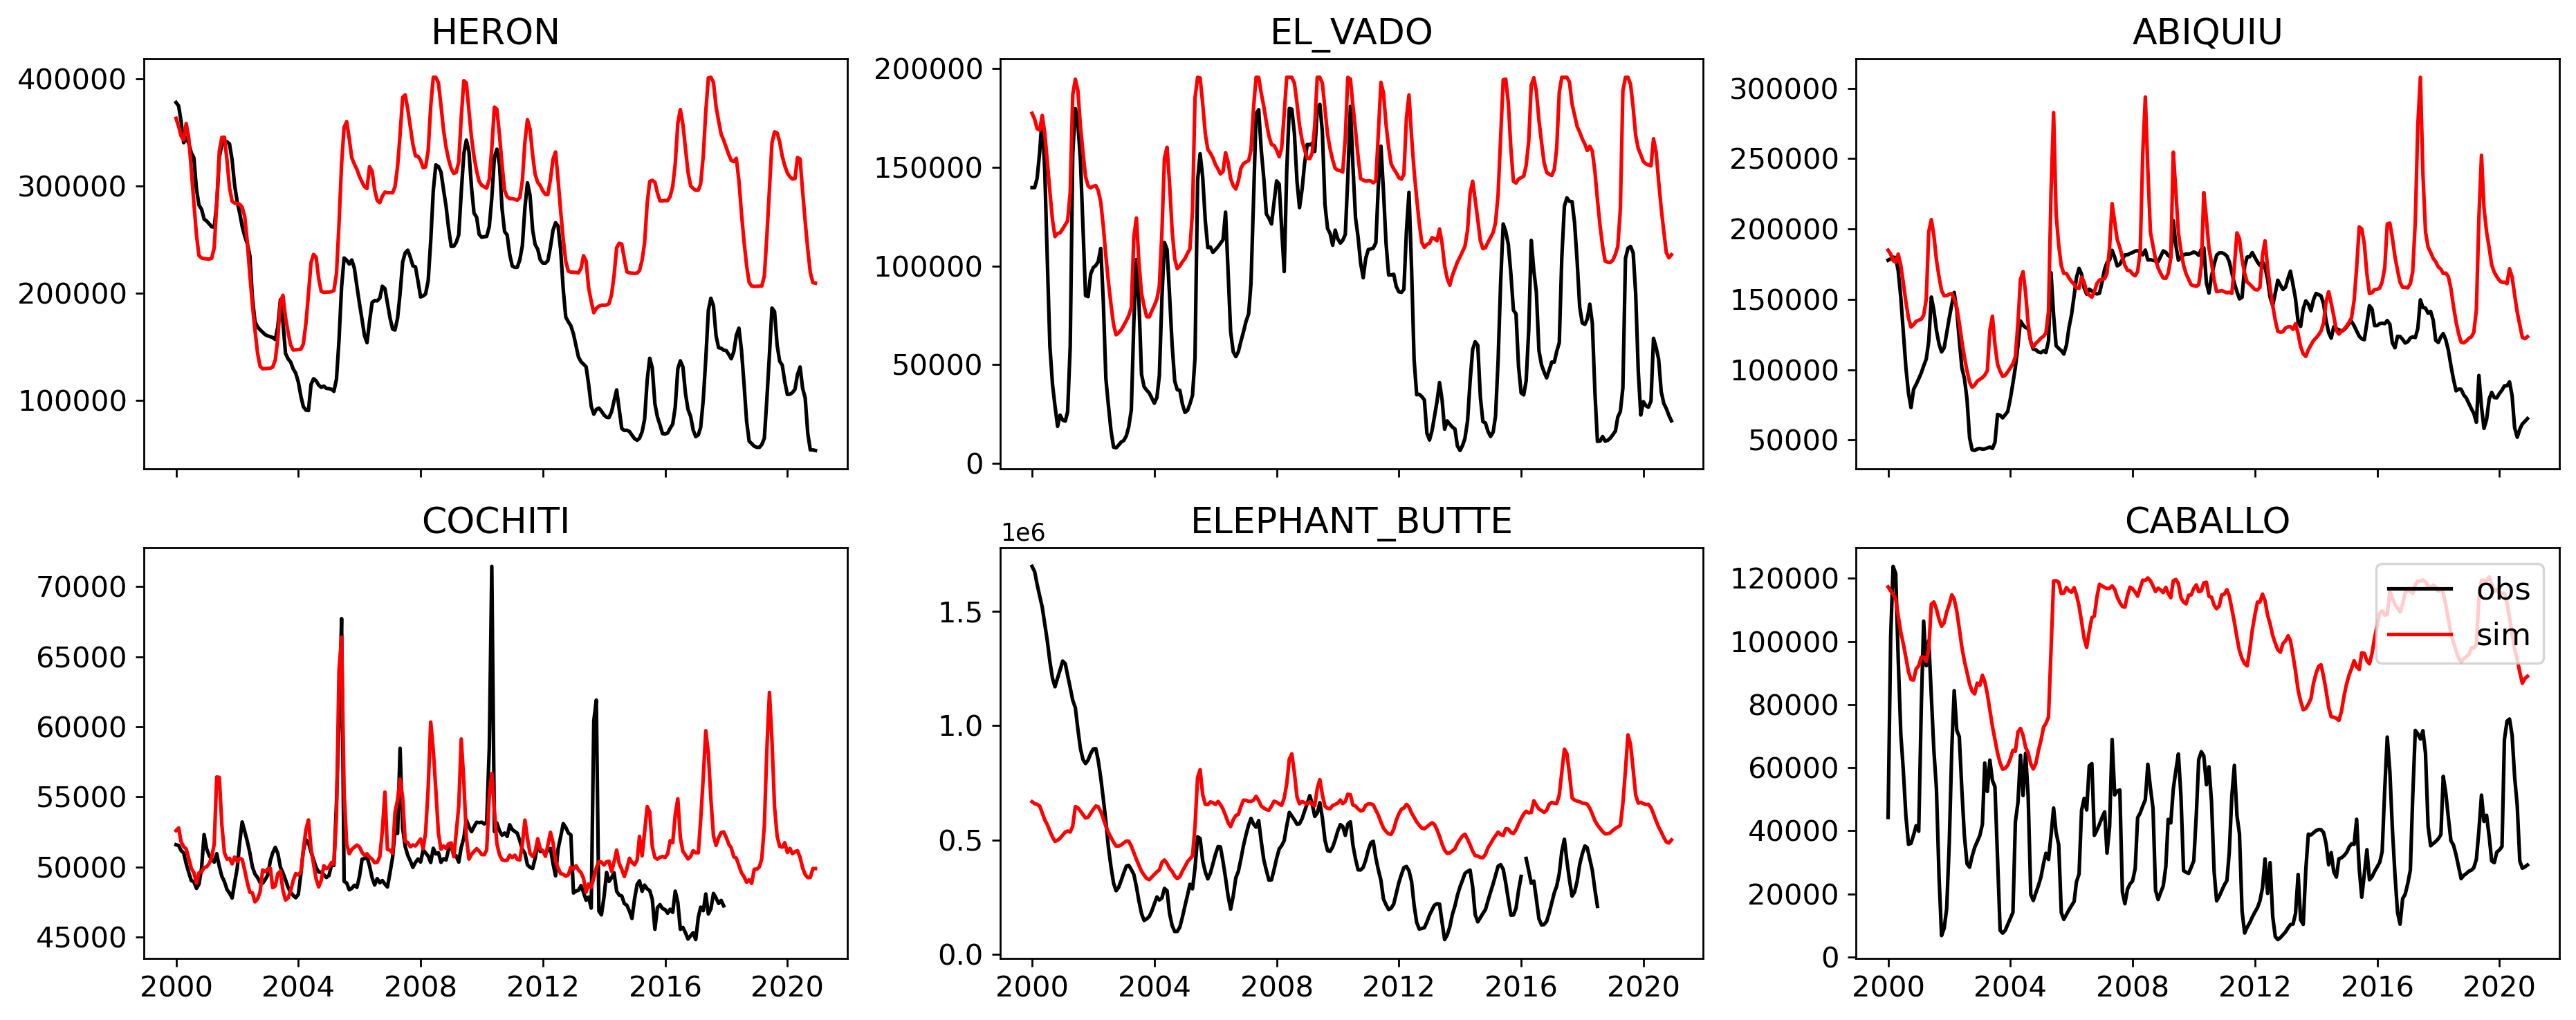

In [60]:
# reservoir storage/releases 
variable = "storage"
variable_bold = "STORAGE"
reservoirs = ["heron", "el_vado", "abiquiu", "cochiti", "elephant_butte", "caballo"]
reservoir_bold = ["HERON", "ELVADO", "ABIQUIU", "COCHITI", "ELEPHANT_BUTTE", "CABALLO"]
capacity = [401300, 190000, 1198500, 589200, 2023400, 350000]
m = 1
fig, axes = plt.subplots(figsize=(15, 6), nrows=2, ncols=3, dpi=250, sharex=True)
axes = axes.ravel()
    
for res_ix in range(len(reservoirs)):
    res = reservoirs[res_ix]
    cap = capacity[res_ix]
    res_bold = reservoir_bold[res_ix]
    print(res_ix, res, res_bold)
    if variable == 'release':
        m = 1.983
    else:
        m = 1
    ax = axes[res_ix]
    obs_data = pd.read_csv("../input/reservoirs/{}/obs_{}.csv".format(res, variable), 
                       index_col=[0], parse_dates=True)
    
    sim_data = results.loc[:, "{}_{}".format(res_bold, variable_bold)] 
    
    # ax.grid(lw=0.5, color='grey', alpha=0.5)
    ax.plot(obs_data.loc["2000":"2020"].resample("MS").mean()*m, color='k', label="obs")
    ax.plot(sim_data.loc["2000":"2020"].resample("MS").mean(), color='red', label="sim")
    
#     ax.set_ylim([0, cap*1.1])
#     ax.axhline(cap, color='grey', linestyle="--", label="capacity")

    ax.tick_params(labelsize=12)
    ax.set_title("{}".format(res.upper()), size=15)
    
ax.legend(fontsize=13, ncol=1, loc='upper right')
plt.tight_layout()

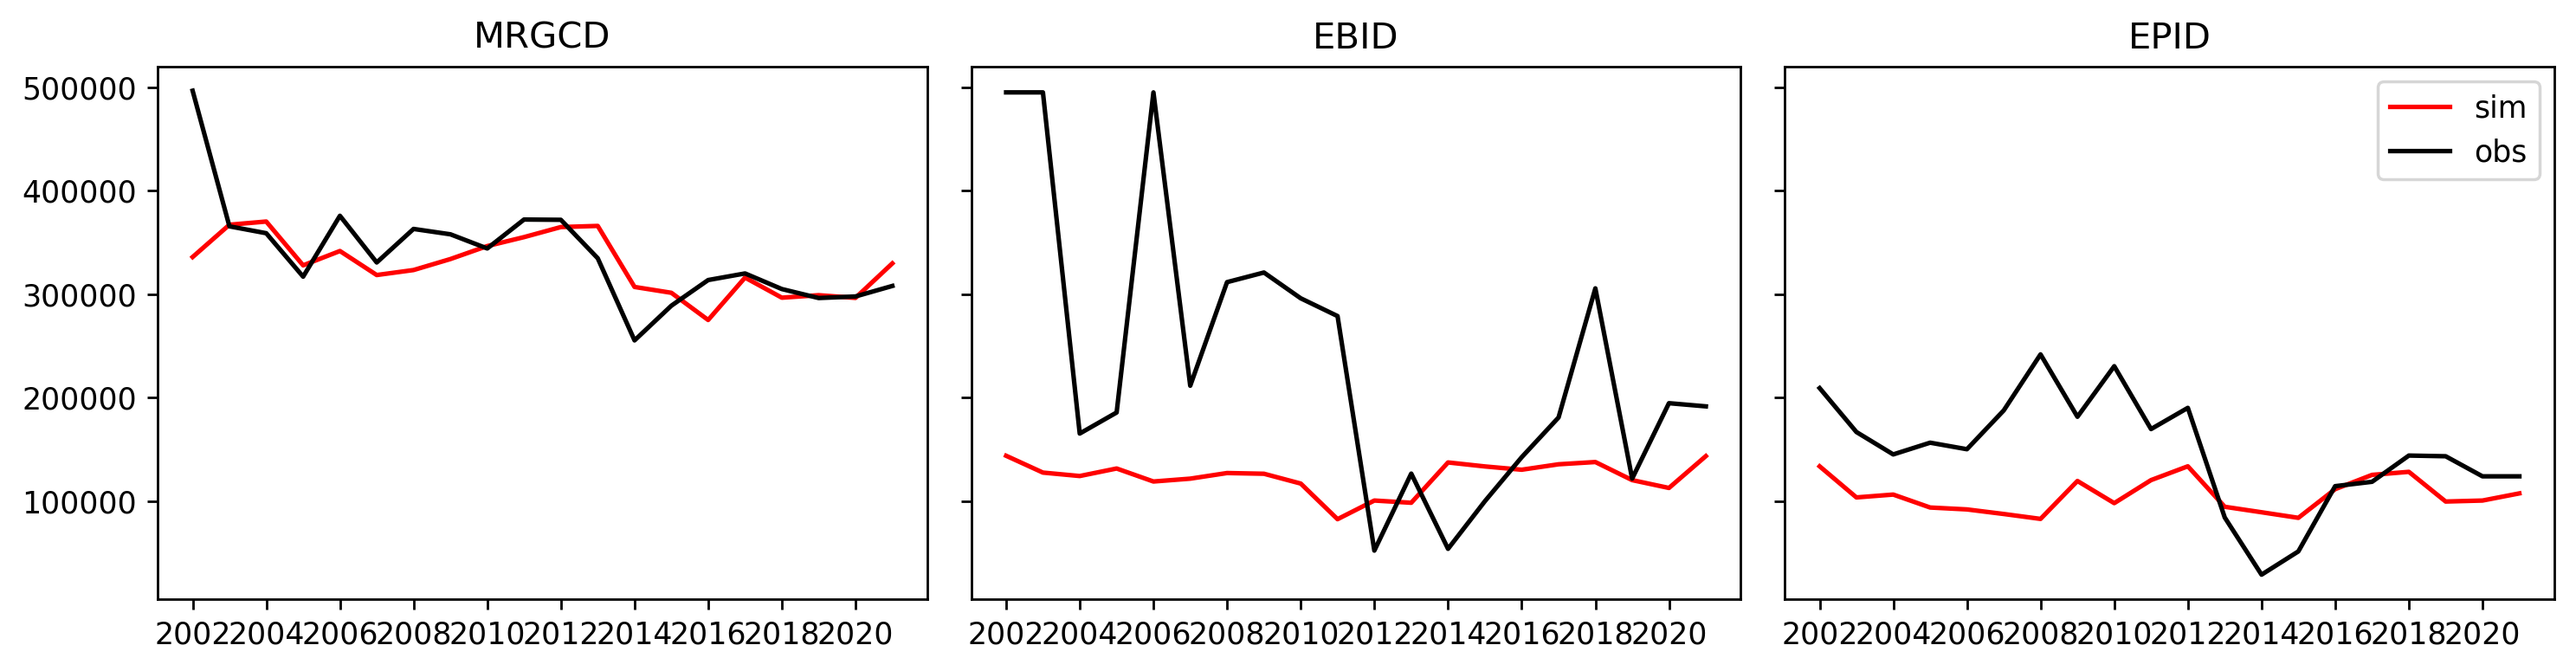

In [54]:
irr_districts = [["ANGDV", "SNADV", "COCDV", "ISLDV"], ["EBID"], ["EPID"]]
mrgcd_withdrawals_obs = pd.read_csv("../data/irr_data/aggregated_withdrawals/mrgcd_total_withdrawals_AF.csv", parse_dates=True, index_col=[0])
ebid_withdrawals_obs = pd.read_csv("../data/irr_data/aggregated_withdrawals/ebid_total_withdrawals_AF.csv", parse_dates=True, index_col=[0])
epid_withdrawals_obs = pd.read_csv("../data/irr_data/aggregated_withdrawals/epid_total_withdrawals_AF.csv", parse_dates=True, index_col=[0]) 

irr_obs_df = [mrgcd_withdrawals_obs, ebid_withdrawals_obs, epid_withdrawals_obs]
irr_name = ["MRGCD", "EBID", "EPID"]
ncols = len(irr_districts)
fig, axes = plt.subplots(figsize=(ncols*4, 3.2), nrows=1, ncols=ncols, dpi=250, sharex=True, sharey='row')
axes = axes.ravel()
for irr_ix in range(len(irr_districts)):
    ax = axes[irr_ix]
    districts_ = irr_districts[irr_ix]
    irr_obs = irr_obs_df[irr_ix]
    # ax.grid()
    ax.plot(results.loc["2001":"2020"].loc[:, ["{}_DIV".format(i) for i in districts_]].sum(1).resample("A").sum(), label="sim", color='r')
    ax.plot(irr_obs.loc[:, districts_].sum(1).resample("A").sum(), label="obs", color='k')
    ax.set_title("{}".format(irr_name[irr_ix]))
plt.tight_layout()
plt.legend()